# 09. Explainable AI — Kinematic và Fusion Kinematic+CWT

**258 participant, group, 6 outer folds, seed 42.** Notebook chỉ đọc kết quả,
không fit/chọn model, feature, task, threshold hay gate. Mọi attribution là outer Test.
Primary TreeSHAP ở **raw log-odds**, không phải xác suất; signed sum và absolute mass khác nhau.
Các case theo nhãn/outcome chỉ dùng minh họa sau đánh giá. XAI không phải bằng chứng nhân quả/lâm sàng.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd() if (Path.cwd()/'results/xai').exists() else Path.cwd().parent
OUT=ROOT/'results/xai'
validation=json.loads((OUT/'validation.json').read_text())
assert validation.get('numerical_validation_passed'), 'Run report_xai.py first'
features=pd.read_csv(OUT/'feature_importance.csv')
groups=pd.read_csv(OUT/'group_importance.csv')
tasks=pd.read_csv(OUT/'task_importance.csv')
fusion=pd.read_csv(OUT/'fusion_participants.csv')
permutation=pd.read_csv(OUT/'permutation_importance.csv')
mapping=pd.read_csv(OUT/'feature_mapping.csv')
manifest=json.loads((OUT/'figures/manifest.json').read_text())
pd.set_option('display.max_columns',None)
pd.set_option('display.float_format','{:.6f}'.format)
print('Read-only XAI. Raw score verified as log-odds for this binary LightGBM.')

Read-only XAI. Raw score verified as log-odds for this binary LightGBM.


## Top Features — bảng số

Mean |SHAP| trên 258 outer Test rows, đơn vị log-odds. CSV feature_importance.csv có đủ 1.036 cột.
top_k_fold_count là số fold thuộc Top-20, không phải tiêu chí chọn lại feature.

In [2]:
display(features[['rank','task','feature','group','sum_mean_abs_shap','fold_sd_mass',
                  'attribution_mass_share_percent','mean_rank','sd_rank','top_k_fold_count']].head(30))

,rank,task,feature,group,sum_mean_abs_shap,fold_sd_mass,attribution_mass_share_percent,mean_rank,sd_rank,top_k_fold_count
0,1.000000,copy,trajectory_width,Trajectory,0.966905,0.118934,7.951176,1.166667,0.408248,6
1,2.000000,copy,fft_pressure_dominant_hz,FFT,0.709768,0.125363,5.836651,2.000000,0.632456,6
2,3.000000,copy,statistics_acc_skew,Statistics,0.466059,0.176833,3.832557,4.833333,2.639444,6
3,4.000000,copy,trajectory_duration,Trajectory,0.418496,0.121644,3.441426,5.500000,3.391165,6
4,5.000000,copy,trajectory_bbox_area,Trajectory,0.386296,0.152826,3.176634,6.833333,3.488075,6
5,6.000000,RCFT-recall,statistics_acc_kurtosis,Statistics,0.358044,0.148160,2.944309,8.166667,5.076088,6
6,7.000000,lower-loops-precise,fft_y_bandwidth_hz,FFT,0.255943,0.065836,2.104706,10.166667,4.915960,6
7,8.000000,dictation,orientation_azimuth_std,Orientation,0.251798,0.128888,2.070619,12.333333,5.853774,6
8,9.000000,lower-loops-fast,pressure_std,Pressure,0.242270,0.077232,1.992264,11.500000,6.774954,5
9,10.000000,dictation,energy_y_rms,Energy,0.236853,0.106698,1.947721,12.666667,7.737355,5


## Top Feature Groups — tổng mass và net contribution

12 nhóm từ prefix thật trong features.py. Mass = E[Σ|φ|]; net magnitude = E[|Σφ|].
Nhóm có số cột khác nhau: xem cả mass/n_features. Đây là aggregation của individual SHAP,
không phải Group Shapley tính bằng joint masker.

In [3]:
display(groups)

,name,n_features,sum_mean_abs_shap,fold_sd_mass,mean_abs_signed_sum,mean_signed_sum,per_feature_mean_abs,mean_rank,sd_rank,top_k_fold_count,attribution_mass_share_percent,rank
0,FFT,224,3.400340,0.373143,1.035377,-0.080664,0.015180,1.166667,0.408248,6,27.962093,1.000000
1,Statistics,140,2.625793,0.267184,0.923456,-0.034254,0.018756,2.166667,0.752773,6,21.592747,2.000000
2,Trajectory,112,2.465493,0.251436,1.415269,-0.002830,0.022013,2.666667,0.516398,6,20.274545,3.000000
3,Orientation,56,1.039268,0.262061,0.518119,-0.010945,0.018558,4.000000,0.000000,0,8.546238,4.000000
4,Pressure,112,0.589001,0.132189,0.305230,-0.038467,0.005259,5.500000,0.547723,0,4.843548,5.000000
5,Acceleration,84,0.473395,0.182866,0.222086,0.003779,0.005636,6.833333,1.602082,0,3.892879,6.000000
6,Energy,42,0.452755,0.144814,0.283085,-0.008422,0.010780,6.666667,1.211060,0,3.723154,7.000000
7,Jerk,42,0.411879,0.104193,0.244729,-0.003595,0.009807,7.666667,1.366260,0,3.387015,8.000000
8,Peaks,42,0.277654,0.080671,0.131056,-0.003125,0.006611,8.833333,1.169045,0,2.283242,9.000000
9,Velocity,112,0.157325,0.032445,0.060283,-0.003038,0.001405,10.500000,0.836660,0,1.293731,10.000000


## Top Tasks và grouped permutation — bảng số đầy đủ

Task order được xác minh từ schema/prepare và tái dựng raw source. Cả 14 task có 74 features.
Permutation drop = baseline metric − metric sau hoán vị, đơn vị điểm phần trăm; số âm được giữ.

In [4]:
display(tasks.merge(permutation[permutation.level=='task'],left_on='name',right_on='block',validate='one_to_one'))
display(pd.read_csv(OUT/'shap_permutation_concordance.csv'))

,name,n_features_x,sum_mean_abs_shap,fold_sd_mass,mean_abs_signed_sum,mean_signed_sum,per_feature_mean_abs,mean_rank,sd_rank,top_k_fold_count,attribution_mass_share_percent,rank,level,block,n_features_y,mean_drop_accuracy_pp,fold_sd_drop_accuracy_pp,mean_drop_f1_macro_pp,fold_sd_drop_f1_macro_pp,mean_drop_auc_pp,fold_sd_drop_auc_pp,mean_drop_balanced_accuracy_pp,fold_sd_drop_balanced_accuracy_pp
0,copy,74,4.297703,0.120311,1.975994,-0.087086,0.058077,1.000000,0.000000,6,35.341398,1.000000,task,copy,74,22.222222,3.611660,23.030039,3.512241,22.900775,4.605751,22.979871,3.506573
1,dictation,74,1.363045,0.225283,0.558853,0.002930,0.018420,2.333333,0.516398,6,11.208761,2.000000,task,dictation,74,2.441860,3.825642,2.500339,3.856679,1.230157,1.572221,2.545369,3.818347
2,lower-loops-fast,74,1.014206,0.207969,0.563326,-0.017777,0.013705,3.666667,1.032796,2,8.340140,3.000000,task,lower-loops-fast,74,3.630491,2.831916,3.676615,2.807989,2.339436,1.581513,3.623655,2.695311
3,small-spiral-fast,74,0.894051,0.148123,0.398385,-0.016040,0.012082,4.333333,0.816497,1,7.352066,4.000000,task,small-spiral-fast,74,2.015504,2.827067,2.066412,2.851251,0.665607,1.003039,2.079011,2.813518
4,RCFT-recall,74,0.868699,0.241988,0.498532,-0.015772,0.011739,4.833333,1.940790,2,7.143591,5.000000,task,RCFT-recall,74,2.416021,2.025863,2.469506,2.006713,0.676795,0.782773,2.475247,1.901685
5,RCFT-recognition,74,0.697872,0.200351,0.301338,-0.030714,0.009431,5.833333,2.041241,1,5.738825,6.000000,task,RCFT-recognition,74,2.751938,1.684687,2.863253,1.725781,0.494247,0.773343,2.931419,1.722371
6,lower-loops-precise,74,0.682151,0.132259,0.315664,-0.015902,0.009218,6.666667,1.366260,0,5.609550,7.000000,task,lower-loops-precise,74,2.080103,2.738274,2.103793,2.809999,0.567326,0.688954,2.053124,2.897647
7,small-spiral-precise,74,0.497038,0.155499,0.263931,0.001207,0.006717,8.833333,1.940790,0,4.087306,8.000000,task,small-spiral-precise,74,0.801034,1.827661,0.800932,1.858432,0.441467,0.758661,0.767046,1.884726
8,big-spiral-fast,74,0.378526,0.072096,0.132034,-0.014646,0.005115,9.833333,1.471960,0,3.112742,9.000000,task,big-spiral-fast,74,0.956072,0.765312,0.972627,0.799395,0.210293,0.583261,0.979733,0.859413
9,rainbow-fast,74,0.307805,0.155557,0.139546,0.022188,0.004160,10.666667,3.076795,0,2.531180,10.000000,task,rainbow-fast,74,1.201550,1.451704,1.208214,1.463980,0.269461,0.225476,1.154346,1.448431


,level,shap_mass_vs_permutation_f1_spearman
0,task,0.916484
1,group,0.881119


## Fold Stability

Spearman giữa các thứ hạng importance và Jaccard Top-k. Train folds chồng lấp;
SD fold không phải CI và 15 cặp fold không phải 15 mẫu độc lập.

In [5]:
display(pd.read_csv(OUT/'fold_stability_summary.csv'))
display(pd.read_csv(OUT/'task_rank_stability.csv'))
with pd.option_context('display.max_rows',None): display(pd.read_csv(OUT/'fold_stability.csv'))

,level,mean_spearman,min_spearman,max_spearman,mean_top_k_jaccard
0,feature,0.314940,0.277718,0.359394,0.416141
1,task,0.822125,0.723077,0.925275,0.566667
2,group,0.913287,0.832168,0.965035,1.000000


,name,n_features,sum_mean_abs_shap,fold_sd_mass,mean_abs_signed_sum,mean_signed_sum,per_feature_mean_abs,mean_rank,sd_rank,top_k_fold_count,attribution_mass_share_percent,rank,fold_0_rank,fold_1_rank,fold_2_rank,fold_3_rank,fold_4_rank,fold_5_rank
0,copy,74,4.297703,0.120311,1.975994,-0.087086,0.058077,1.000000,0.000000,6,35.341398,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,dictation,74,1.363045,0.225283,0.558853,0.002930,0.018420,2.333333,0.516398,6,11.208761,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000
2,lower-loops-fast,74,1.014206,0.207969,0.563326,-0.017777,0.013705,3.666667,1.032796,2,8.340140,3.000000,4.000000,4.000000,2.000000,3.000000,5.000000,4.000000
3,small-spiral-fast,74,0.894051,0.148123,0.398385,-0.016040,0.012082,4.333333,0.816497,1,7.352066,4.000000,5.000000,3.000000,5.000000,4.000000,4.000000,5.000000
4,RCFT-recall,74,0.868699,0.241988,0.498532,-0.015772,0.011739,4.833333,1.940790,2,7.143591,5.000000,3.000000,5.000000,4.000000,8.000000,6.000000,3.000000
5,RCFT-recognition,74,0.697872,0.200351,0.301338,-0.030714,0.009431,5.833333,2.041241,1,5.738825,6.000000,7.000000,6.000000,6.000000,6.000000,2.000000,8.000000
6,lower-loops-precise,74,0.682151,0.132259,0.315664,-0.015902,0.009218,6.666667,1.366260,0,5.609550,7.000000,6.000000,7.000000,7.000000,5.000000,9.000000,6.000000
7,small-spiral-precise,74,0.497038,0.155499,0.263931,0.001207,0.006717,8.833333,1.940790,0,4.087306,8.000000,8.000000,12.000000,10.000000,9.000000,7.000000,7.000000
8,big-spiral-fast,74,0.378526,0.072096,0.132034,-0.014646,0.005115,9.833333,1.471960,0,3.112742,9.000000,12.000000,8.000000,9.000000,10.000000,11.000000,9.000000
9,rainbow-fast,74,0.307805,0.155557,0.139546,0.022188,0.004160,10.666667,3.076795,0,2.531180,10.000000,14.000000,9.000000,8.000000,7.000000,12.000000,14.000000


,level,fold_a,fold_b,spearman,top_k,top_k_jaccard
0,feature,0,1,0.314819,20,0.428571
1,feature,0,2,0.277718,20,0.428571
2,feature,0,3,0.289992,20,0.481481
3,feature,0,4,0.307849,20,0.481481
4,feature,0,5,0.292016,20,0.379310
5,feature,1,2,0.322075,20,0.333333
6,feature,1,3,0.356060,20,0.428571
7,feature,1,4,0.358440,20,0.428571
8,feature,1,5,0.359394,20,0.379310
9,feature,2,3,0.301904,20,0.428571


## Kiểm chứng raw score / log-odds / probability

Không sigmoid từng SHAP value. Probability SHAP có reference và đơn vị riêng.
SHAP interventional dùng lossless encoding của các partition cây để tránh rounding threshold
float32 của backend; mọi split, model output và masked coalition được bảo toàn, model gốc không đổi.
Xem REPORT_VI.md và unit test ranh giới ngưỡng. Background chỉ lấy từ outer Train.

In [6]:
checks=pd.read_csv(OUT/'output_space_checks.csv')
display(checks.head(12))
print('Max raw additivity error:',float((checks.raw_score-checks.raw_path_reconstructed).abs().max()))
print('Max probability additivity error:',float((checks.probability-checks.probability_reconstructed).abs().max()))
display(pd.read_csv(OUT/'explainer_sensitivity.csv'))
display(pd.DataFrame(json.loads((OUT/'mapping_audit.json').read_text())['sentinels']))

,participant_id,fold,label,prediction,probability,raw_score,raw_path_reconstructed,raw_interventional_reconstructed,probability_reconstructed,sigmoid_raw_score,interventional_raw_base,sigmoid_interventional_raw_base,probability_base
0,BR10301,4,0,0,0.249635,-1.100558,-1.100558,-1.100558,0.249635,0.249635,0.788697,0.687551,0.549961
1,BR10302,0,0,0,0.046320,-3.024765,-3.024765,-3.024765,0.046320,0.046320,0.517885,0.626653,0.530219
2,BR10304,2,0,0,0.008734,-4.731780,-4.731780,-4.731780,0.008734,0.008734,0.749522,0.679075,0.559857
3,BR10305,3,0,0,0.138935,-1.824160,-1.824160,-1.824160,0.138935,0.138935,0.829127,0.696170,0.550196
4,BR10306,5,1,1,0.996677,5.703634,5.703634,5.703634,0.996677,0.996677,0.588222,0.642957,0.540061
5,BR10403,0,0,0,0.025581,-3.640010,-3.640010,-3.640010,0.025581,0.025581,0.517885,0.626653,0.530219
6,BR10404,2,0,0,0.008390,-4.772250,-4.772250,-4.772250,0.008390,0.008390,0.749522,0.679075,0.559857
7,BR10405,3,0,0,0.376719,-0.503497,-0.503497,-0.503497,0.376719,0.376719,0.829127,0.696170,0.550196
8,BR10406,0,1,1,0.991508,4.760157,4.760157,4.760157,0.991508,0.991508,0.517885,0.626653,0.530219
9,BR2401,3,0,0,0.028684,-3.522314,-3.522314,-3.522315,0.028684,0.028684,0.829127,0.696170,0.550196


Max raw additivity error: 7.105427357601002e-15
Max probability additivity error: 5.672131000132585e-09


,level,raw_path_vs_interventional_raw_spearman,interventional_raw_vs_probability_spearman
0,feature,0.999434,0.999432
1,task,1.000000,0.995604
2,group,1.000000,0.986014


,participant_id,source,source_sha256,tasks_checked,features_checked,max_abs_difference
0,BR10301,data\clean_data\BR10301_merged.json,acbf776c241da5904a32ce7a711b2b441877ea54711084...,14,1036,0.000000
1,DK12402,data\clean_data\DK12402_merged.json,1dedfa00bf74383e3a182e718c8828a18c5c011ff5f3f2...,14,1036,0.000000
2,VV10404,data\clean_data\VV10404_merged.json,eb4c328074f3cf89386f90d812a7bb76a574f9fe4ac09e...,14,1036,0.000000


## Fusion — cấu hình và corrected/harmed

Late trộn xác suất với trọng số simplex; không có gate. Adaptive là confidence-gated probability
correction: Δp_CWT = 1[|pK−0.5|≤τ] × α × (pC−pK). Không phải learned attention network.
Δp so với baseline không phải SHAP của modality. Gate/weights không được chọn lại bằng XAI.

In [7]:
display(pd.read_csv(OUT/'fusion_fold_mechanisms.csv'))
display(pd.read_csv(OUT/'fusion_outcome_summary.csv'))
with pd.option_context('display.max_rows',None): display(pd.read_csv(OUT/'fusion_corrected_harmed_cases.csv'))

,scenario,fold,cwt_reducer,cwt_dimensions,mean_effective_cwt_weight,gate_threshold,budget,mean_abs_delta_cwt
0,late__KC,0,none,25088,0.225293,NaN,NaN,0.086510
1,adaptive__KC,0,pca_var99,204,0.069767,0.100000,0.500000,0.019851
2,late__KC,1,pca_var99,203,0.283853,NaN,NaN,0.082901
3,adaptive__KC,1,pca_var99,203,0.023256,0.100000,0.250000,0.008805
4,late__KC,2,none,25088,0.275306,NaN,NaN,0.091880
5,adaptive__KC,2,none,25088,0.093023,0.250000,0.500000,0.045127
6,late__KC,3,none,25088,0.207738,NaN,NaN,0.059522
7,adaptive__KC,3,pca_var99,203,0.011628,0.100000,0.250000,0.005434
8,late__KC,4,none,25088,0.300294,NaN,NaN,0.109868
9,adaptive__KC,4,pca_var99,204,0.058140,0.250000,0.250000,0.022087


,scenario,outcome,n,mean_kinematic_probability,mean_cwt_probability,mean_fusion_probability,mean_delta_cwt,mean_effective_cwt_weight
0,late__KC,unchanged_correct,211,0.561366,0.534848,0.555330,-0.006036,0.247830
1,late__KC,unchanged_wrong,30,0.497572,0.552237,0.506014,0.008442,0.246539
2,late__KC,harmed,8,0.493553,0.489426,0.491682,-0.001871,0.261953
3,late__KC,corrected,9,0.482811,0.501417,0.493349,0.010537,0.272719
4,adaptive__KC,unchanged_correct,213,0.556728,0.562115,0.559128,0.002401,0.036385
5,adaptive__KC,unchanged_wrong,31,0.493010,0.550326,0.496182,0.003171,0.032258
6,adaptive__KC,corrected,8,0.498644,0.489004,0.477785,-0.020858,0.406250
7,adaptive__KC,harmed,6,0.635616,0.061918,0.391891,-0.243724,0.416667


,scenario,fold,participant_id,label,candidate,cwt_reducer,cwt_dimensions,kinematic_probability,cwt_probability,fusion_probability,kinematic_prediction,cwt_prediction,fusion_prediction,effective_weight_kinematic,effective_weight_cwt,nominal_weights,gate_applicable,gate_active,gate_threshold,budget,delta_cwt,kinematic_uncertainty_distance,moves_toward_observed_label,outcome,gate_status
0,late__KC,0,BR3402,0,late__KC__K__none__LightGBM__C__none__Logistic...,none,25088,0.363918,0.985306,0.503912,0,1,1,0.774707,0.225293,"[0.7747074100400425, 0.2252925899599575]",False,NaN,NaN,NaN,0.139994,0.136082,-0.139994,harmed,not_applicable
1,late__KC,0,BR8414,0,late__KC__K__none__LightGBM__C__none__Logistic...,none,25088,0.475153,0.761597,0.539687,0,1,1,0.774707,0.225293,"[0.7747074100400425, 0.2252925899599575]",False,NaN,NaN,NaN,0.064534,0.024847,-0.064534,harmed,not_applicable
2,late__KC,0,TL10401,1,late__KC__K__none__LightGBM__C__none__Logistic...,none,25088,0.487942,0.772162,0.551975,0,1,1,0.774707,0.225293,"[0.7747074100400425, 0.2252925899599575]",False,NaN,NaN,NaN,0.064033,0.012058,0.064033,corrected,not_applicable
3,adaptive__KC,0,TL10401,1,adaptive__KC__K__none__LightGBM__C__pca_var99_...,pca_var99,204,0.487942,0.924389,0.706165,0,1,1,0.500000,0.500000,[1.0],True,True,0.100000,0.500000,0.218223,0.012058,0.218223,corrected,active
4,late__KC,1,BR5301,0,late__KC__K__none__LightGBM__C__pca_var99__Log...,pca_var99,203,0.667433,0.000062,0.477998,1,0,0,0.716147,0.283853,"[0.7161471573896571, 0.2838528426103429]",False,NaN,NaN,NaN,-0.189435,0.167433,0.189435,corrected,not_applicable
5,late__KC,1,BR7401,0,late__KC__K__none__LightGBM__C__pca_var99__Log...,pca_var99,203,0.372632,0.998452,0.550273,0,1,1,0.716147,0.283853,"[0.7161471573896571, 0.2838528426103429]",False,NaN,NaN,NaN,0.177641,0.127368,-0.177641,harmed,not_applicable
6,late__KC,1,NA06306,1,late__KC__K__none__LightGBM__C__pca_var99__Log...,pca_var99,203,0.328503,0.999780,0.519047,0,1,1,0.716147,0.283853,"[0.7161471573896571, 0.2838528426103429]",False,NaN,NaN,NaN,0.190544,0.171497,0.190544,corrected,not_applicable
7,late__KC,1,NA06404,1,late__KC__K__none__LightGBM__C__pca_var99__Log...,pca_var99,203,0.455909,0.956829,0.598097,0,1,1,0.716147,0.283853,"[0.7161471573896571, 0.2838528426103429]",False,NaN,NaN,NaN,0.142187,0.044091,0.142187,corrected,not_applicable
8,late__KC,1,TU03403,1,late__KC__K__none__LightGBM__C__pca_var99__Log...,pca_var99,203,0.575162,0.108707,0.442758,1,0,0,0.716147,0.283853,"[0.7161471573896571, 0.2838528426103429]",False,NaN,NaN,NaN,-0.132404,0.075162,-0.132404,harmed,not_applicable
9,adaptive__KC,1,NA06404,1,adaptive__KC__K__none__LightGBM__C__pca_var99_...,pca_var99,203,0.455909,0.956829,0.581139,0,1,1,0.750000,0.250000,[1.0],True,True,0.100000,0.250000,0.125230,0.044091,0.125230,corrected,active


## Mỗi participant: pK, pC, pFusion, weight, gate và Δp

Đủ 516 hàng. Gate_status của Late là not_applicable, tránh hiểu nhầm Late có confidence gate.

In [8]:
columns=['scenario','fold','participant_id','label','kinematic_probability','cwt_probability','fusion_probability',
         'effective_weight_kinematic','effective_weight_cwt','gate_status','gate_threshold','budget','delta_cwt','outcome']
with pd.option_context('display.max_rows',None): display(fusion[columns].sort_values(['scenario','fold','participant_id']).reset_index(drop=True))

,scenario,fold,participant_id,label,kinematic_probability,cwt_probability,fusion_probability,effective_weight_kinematic,effective_weight_cwt,gate_status,gate_threshold,budget,delta_cwt,outcome
0,adaptive__KC,0,BR10302,0,0.046320,0.928380,0.046320,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_correct
1,adaptive__KC,0,BR10403,0,0.025581,0.794102,0.025581,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_correct
2,adaptive__KC,0,BR10406,1,0.991508,0.372335,0.991508,1.000000,0.000000,inactive,0.100000,0.500000,-0.000000,unchanged_correct
3,adaptive__KC,0,BR2403,0,0.351217,0.662653,0.351217,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_correct
4,adaptive__KC,0,BR2408,0,0.610705,0.999999,0.610705,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_wrong
5,adaptive__KC,0,BR2409,0,0.059675,0.767624,0.059675,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_correct
6,adaptive__KC,0,BR3304,0,0.101650,0.000114,0.101650,1.000000,0.000000,inactive,0.100000,0.500000,-0.000000,unchanged_correct
7,adaptive__KC,0,BR3402,0,0.363918,0.996632,0.363918,1.000000,0.000000,inactive,0.100000,0.500000,0.000000,unchanged_correct
8,adaptive__KC,0,BR3407,0,0.413685,0.104508,0.259096,0.500000,0.500000,active,0.100000,0.500000,-0.154589,unchanged_correct
9,adaptive__KC,0,BR5303,0,0.324316,0.014817,0.324316,1.000000,0.000000,inactive,0.100000,0.500000,-0.000000,unchanged_correct


## CWT component attribution — chỉ ở embedding/PCA

Model CWT là LogisticRegression. Linear contribution cộng về log-odds CWT, không phải probability
contribution của Fusion. PC1 của hai fold không phải cùng một tọa độ; không gộp hoặc gán cho
tác vụ/tín hiệu/ý nghĩa sinh học. Bảng giữ fold và reducer rõ ràng.

In [9]:
components=pd.read_csv(OUT/'cwt_component_importance.csv')
with pd.option_context('display.max_rows',None): display(components[components.reducer.str.startswith('pca')].reset_index(drop=True))

,scenario,fold,reducer,component_index,rank,component,mean_abs_logit_contribution,mean_logit_contribution,biological_interpretation_available
0,adaptive__KC,0,pca_var99,2,1,fold0_PC003,1.989743,-0.500748,False
1,adaptive__KC,0,pca_var99,11,2,fold0_PC012,1.896315,0.582273,False
2,adaptive__KC,0,pca_var99,4,3,fold0_PC005,1.316316,0.083544,False
3,adaptive__KC,0,pca_var99,10,4,fold0_PC011,0.940405,0.128909,False
4,adaptive__KC,0,pca_var99,33,5,fold0_PC034,0.893135,-0.015118,False
5,adaptive__KC,0,pca_var99,9,6,fold0_PC010,0.866030,0.291686,False
6,adaptive__KC,0,pca_var99,1,7,fold0_PC002,0.848639,-0.131689,False
7,adaptive__KC,0,pca_var99,37,8,fold0_PC038,0.809814,-0.068060,False
8,adaptive__KC,0,pca_var99,7,9,fold0_PC008,0.801442,-0.157592,False
9,adaptive__KC,0,pca_var99,21,10,fold0_PC022,0.784515,-0.247982,False


## Hình SHAP phục vụ paper

Summary và Beeswarm là hai cách trình bày cùng dữ liệu, không phải hai kiểm chứng độc lập.
Hình dependence là quan hệ quan sát X–SHAP; không phải hiệu ứng can thiệp.

**shap_summary** — Legacy summary of fixed OOF TreeSHAP; same evidence as modern beeswarm. Units: log-odds

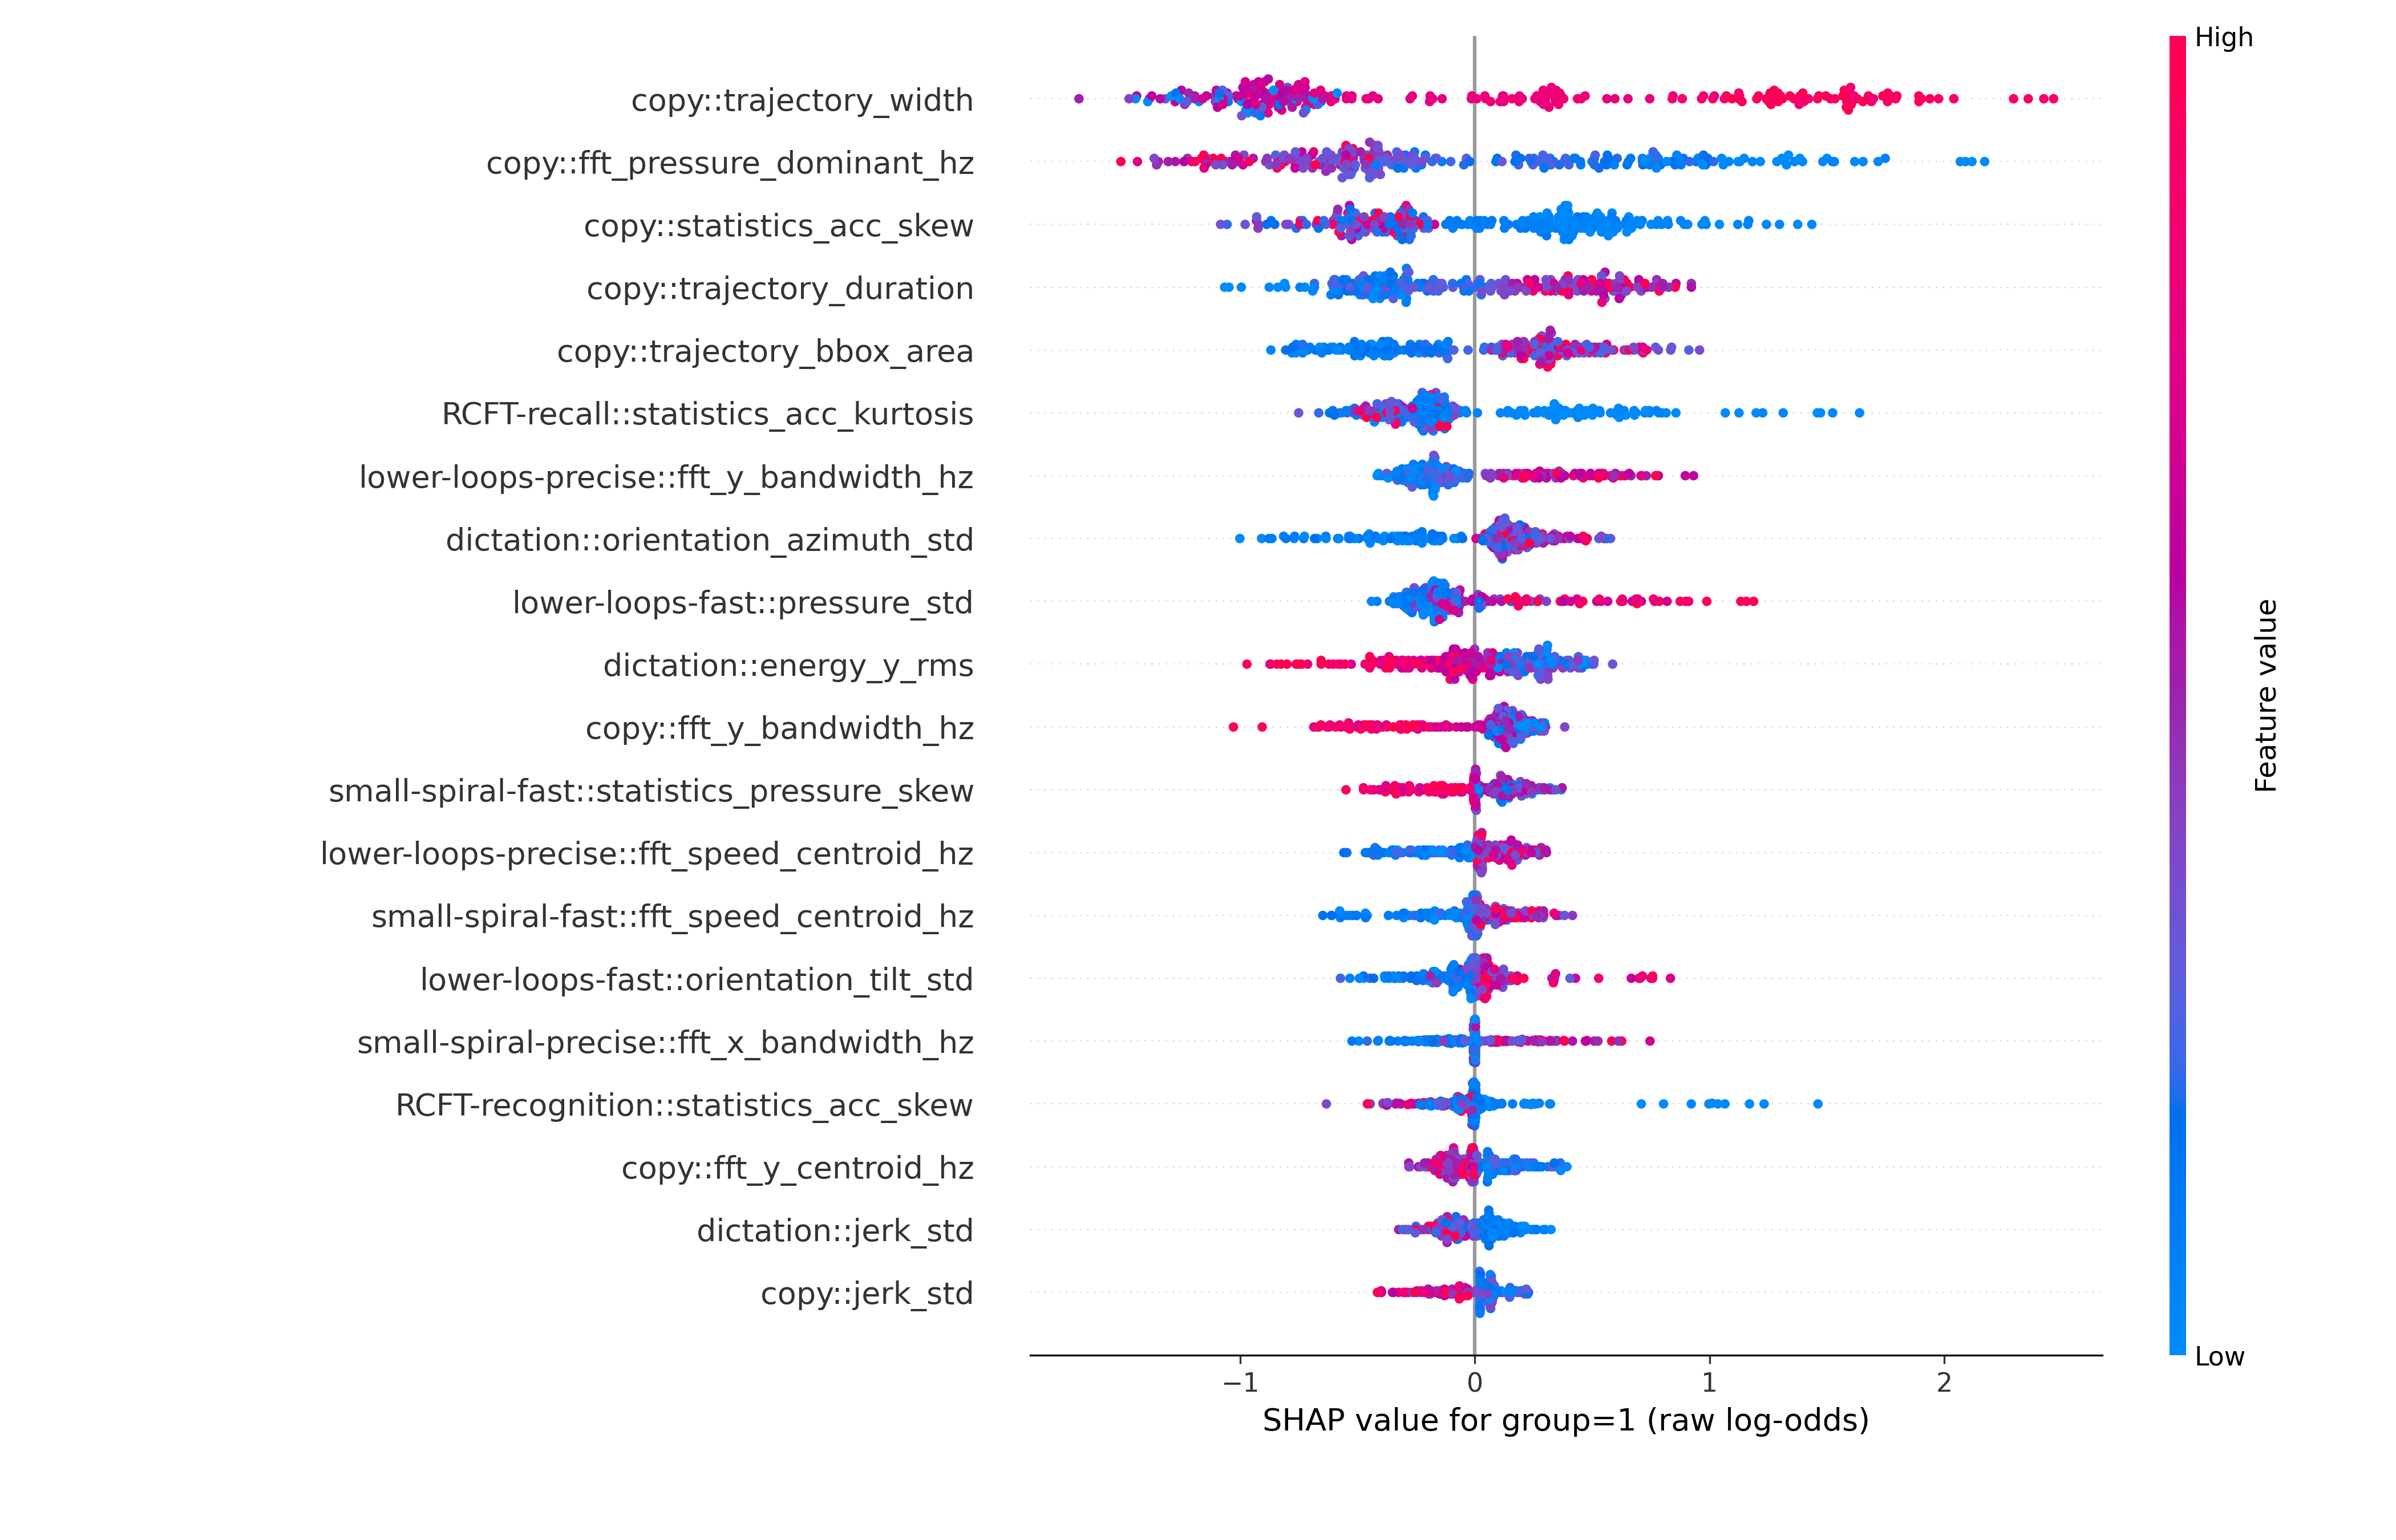

**shap_beeswarm** — Modern beeswarm, 258 held-out rows from six fixed models. Units: log-odds; color = raw input value

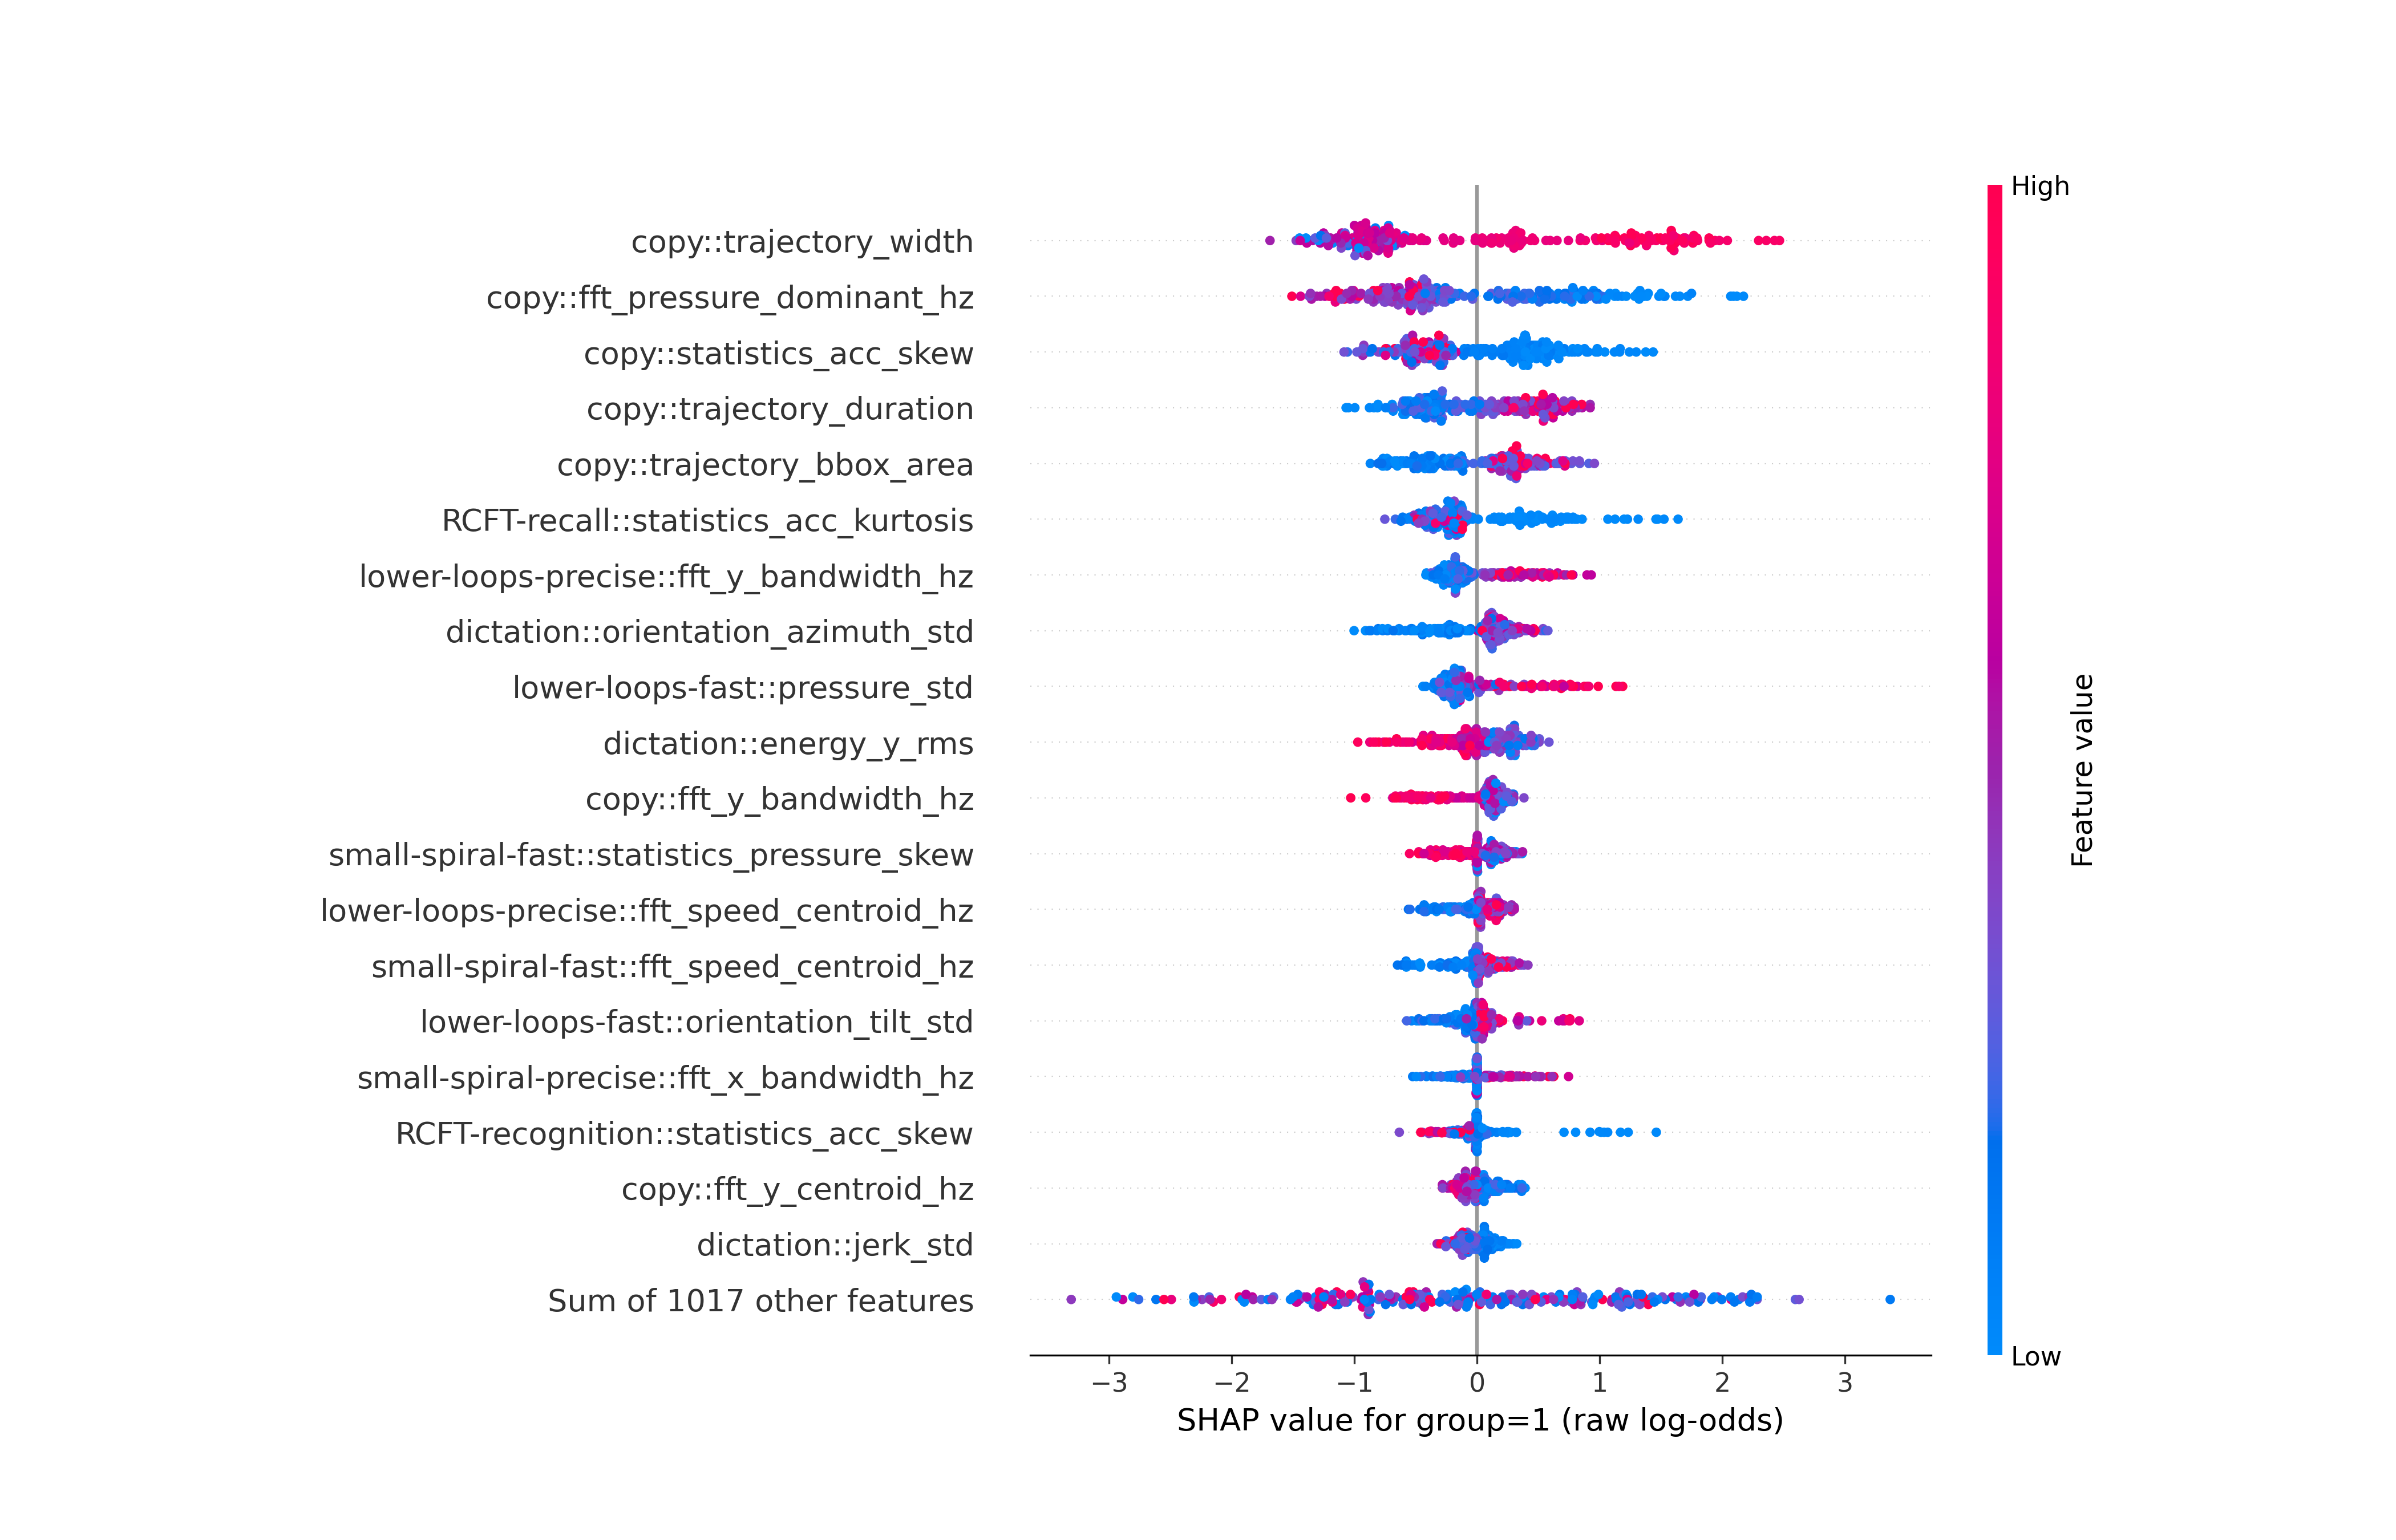

**shap_bar** — Global mean absolute feature contributions; not causal importance. Units: mean absolute log-odds

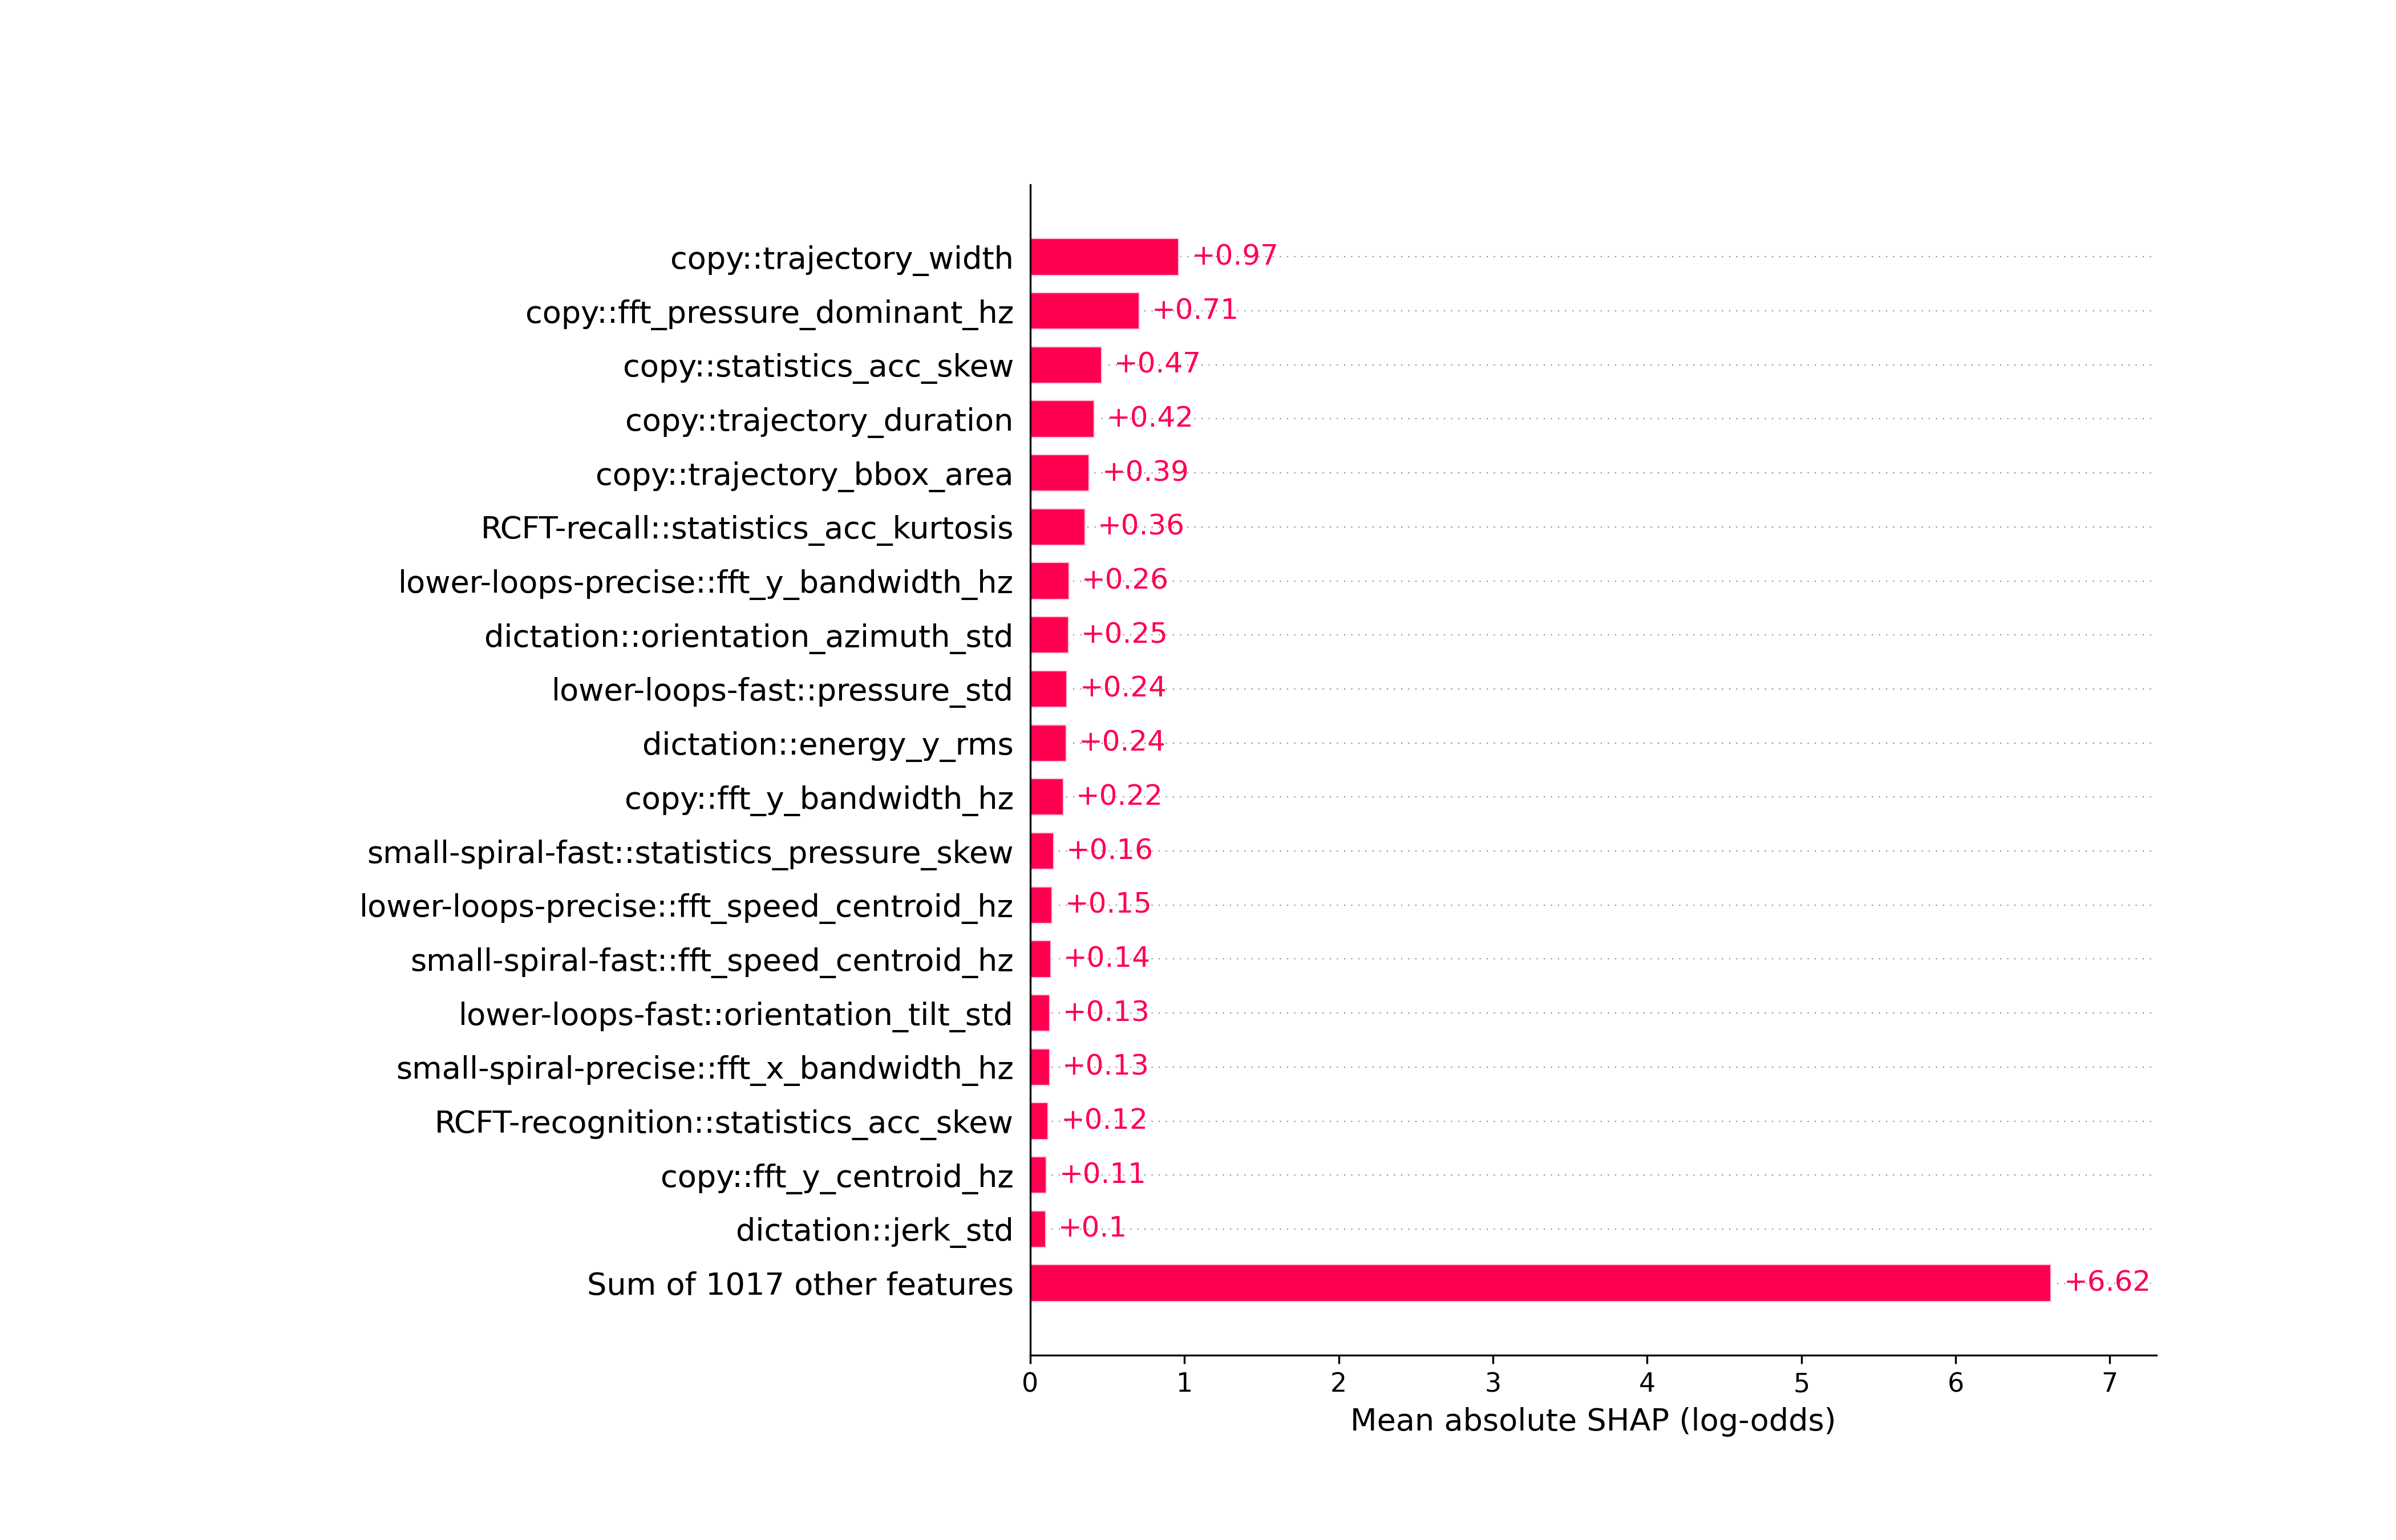

**shap_dependence** — Highest mass feature dependence scatter, descriptive post-hoc feature choice. Units: raw feature units versus log-odds

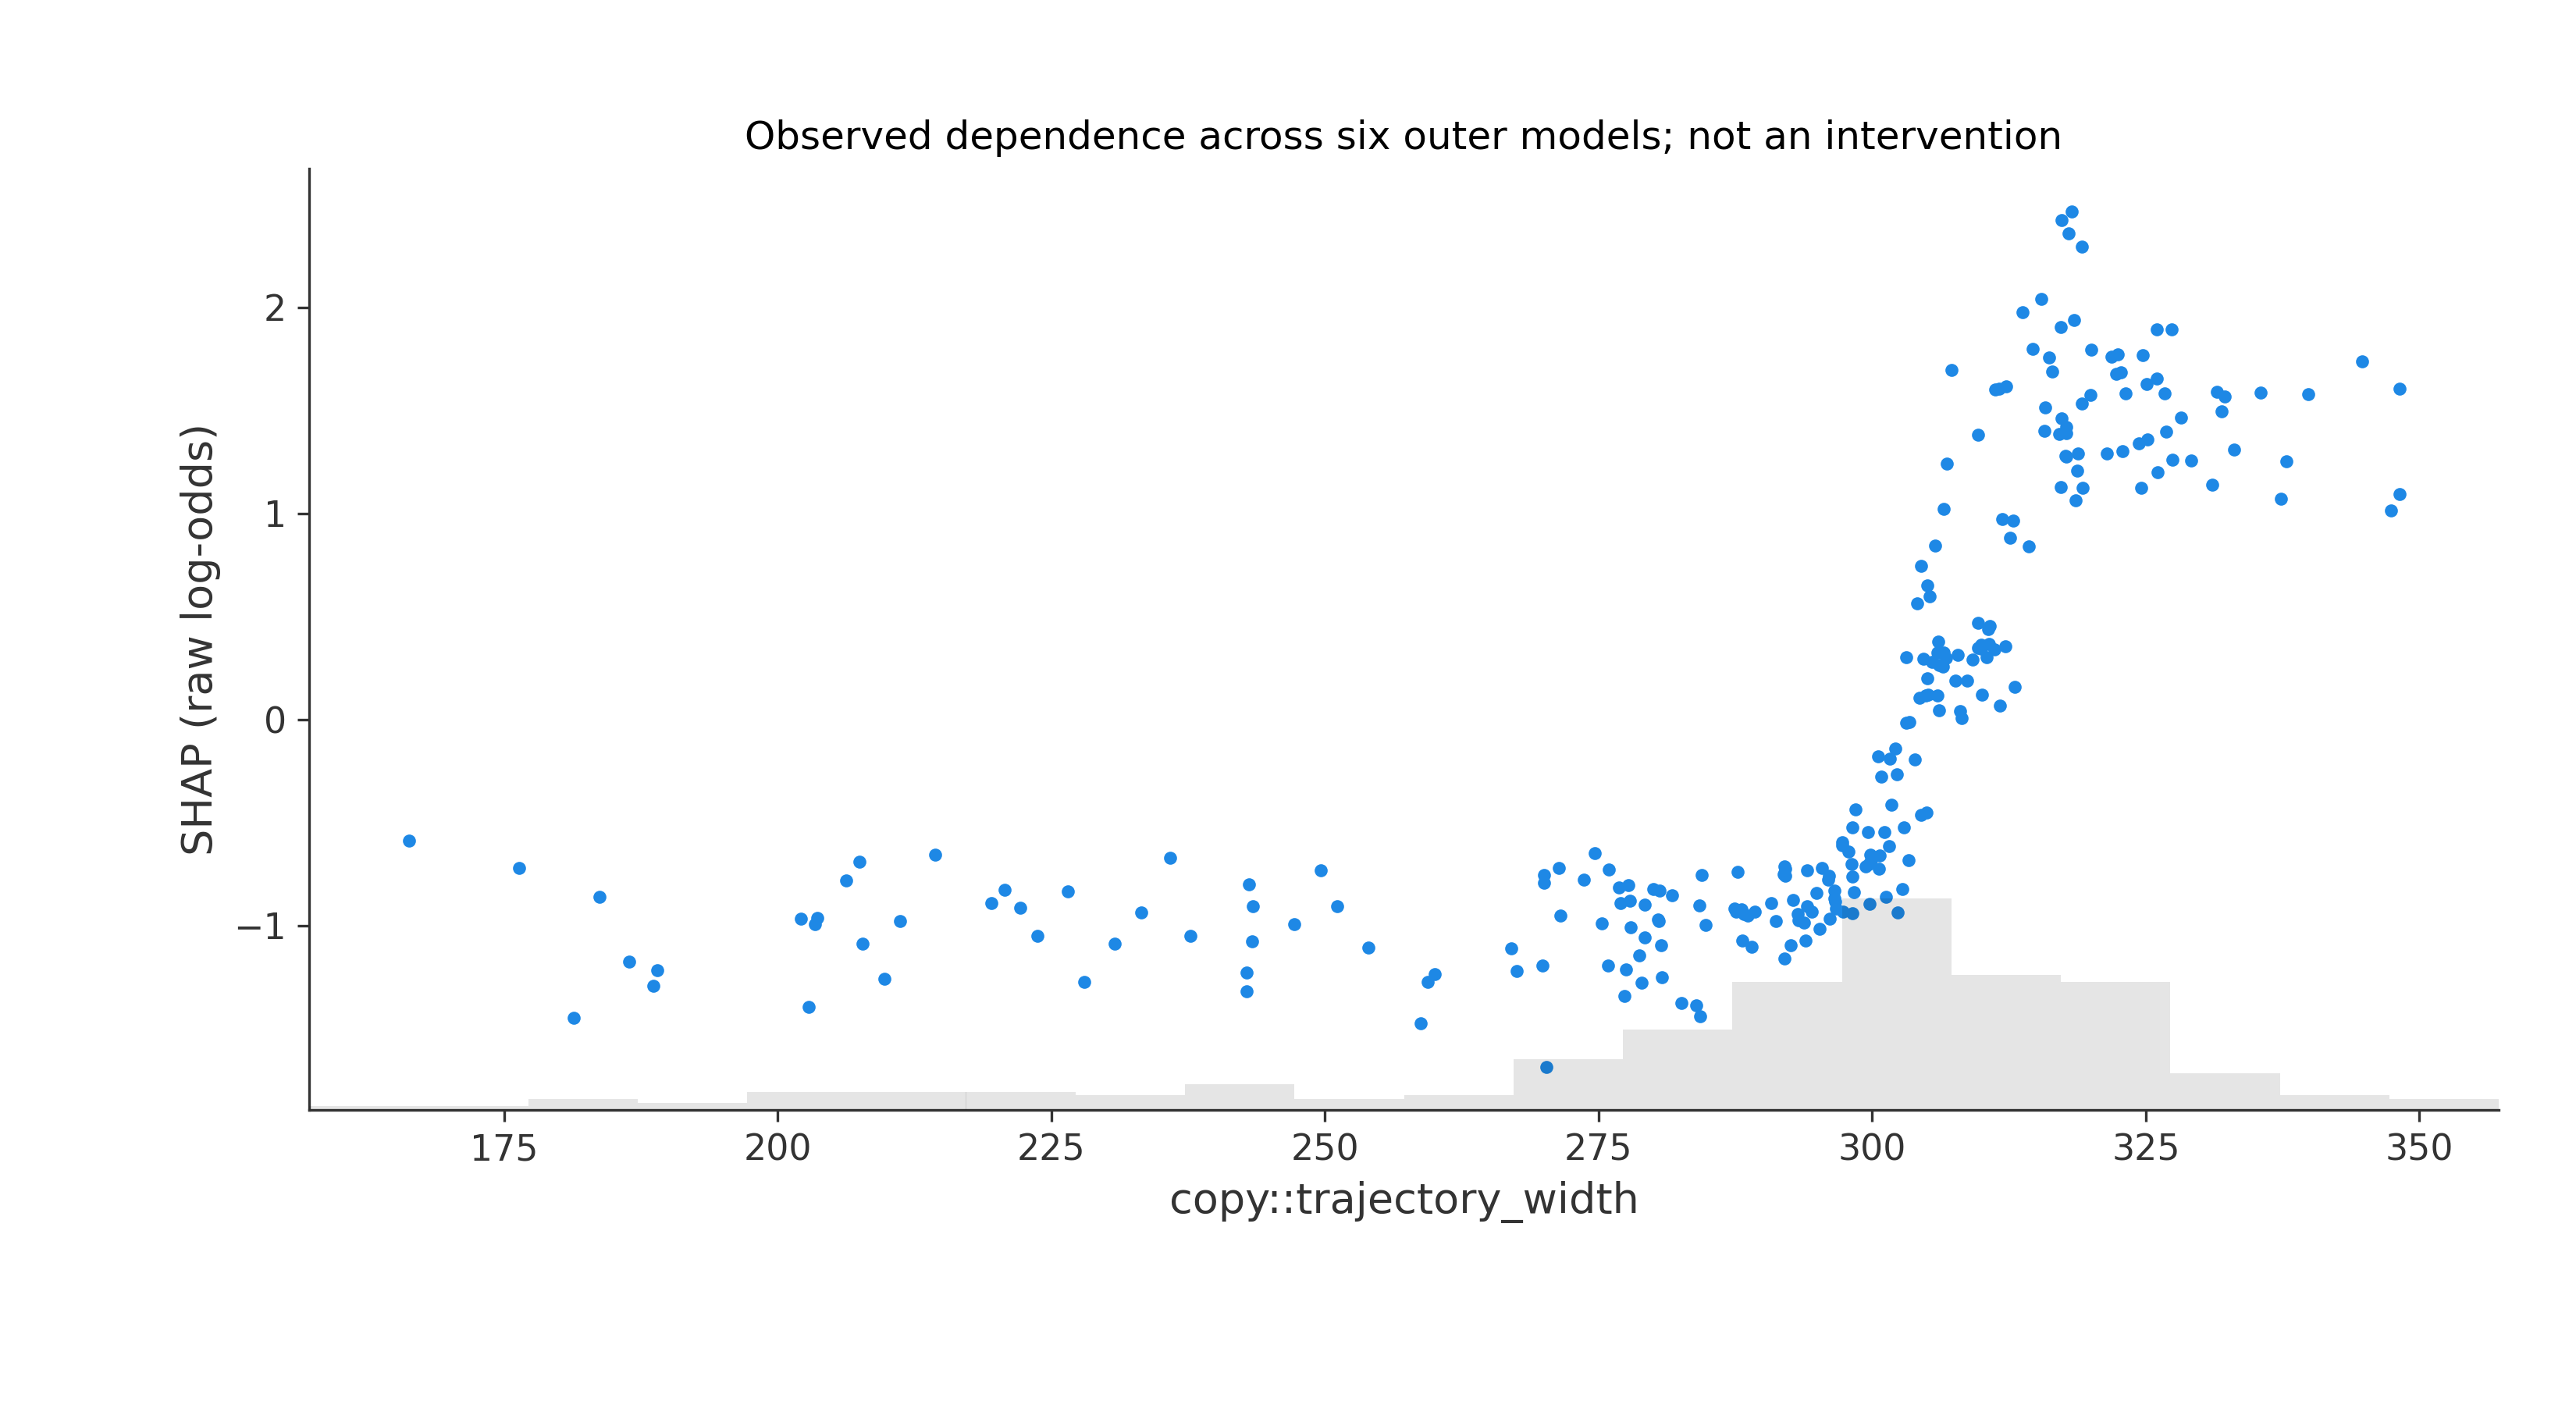

In [10]:
def show_figures(names):
    for name in names:
        item=next(x for x in manifest if x['name']==name)
        display(Markdown('**'+name+'** — '+item['description']+' Units: '+item['units']))
        display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1100))
show_figures(['shap_summary','shap_beeswarm','shap_bar','shap_dependence'])

## Local explanations — cả đúng, sai, corrected và harmed

Case là participant đầu theo ID trong từng outcome Adaptive, chọn hậu nghiệm chỉ để minh họa.
Waterfall giải thích Kinematic log-odds, không phải feature-level SHAP của Fusion.

,outcome,participant_id,fold,selection_rule
0,corrected,BR2404,5,first lexicographic participant in category; p...
1,harmed,DK12401,2,first lexicographic participant in category; p...
2,unchanged_correct,BR10301,4,first lexicographic participant in category; p...
3,unchanged_wrong,BR2408,0,first lexicographic participant in category; p...


**waterfall_corrected** — First lexicographic participant in outcome; explanation of Kinematic, not feature SHAP of Fusion. Units: raw log-odds

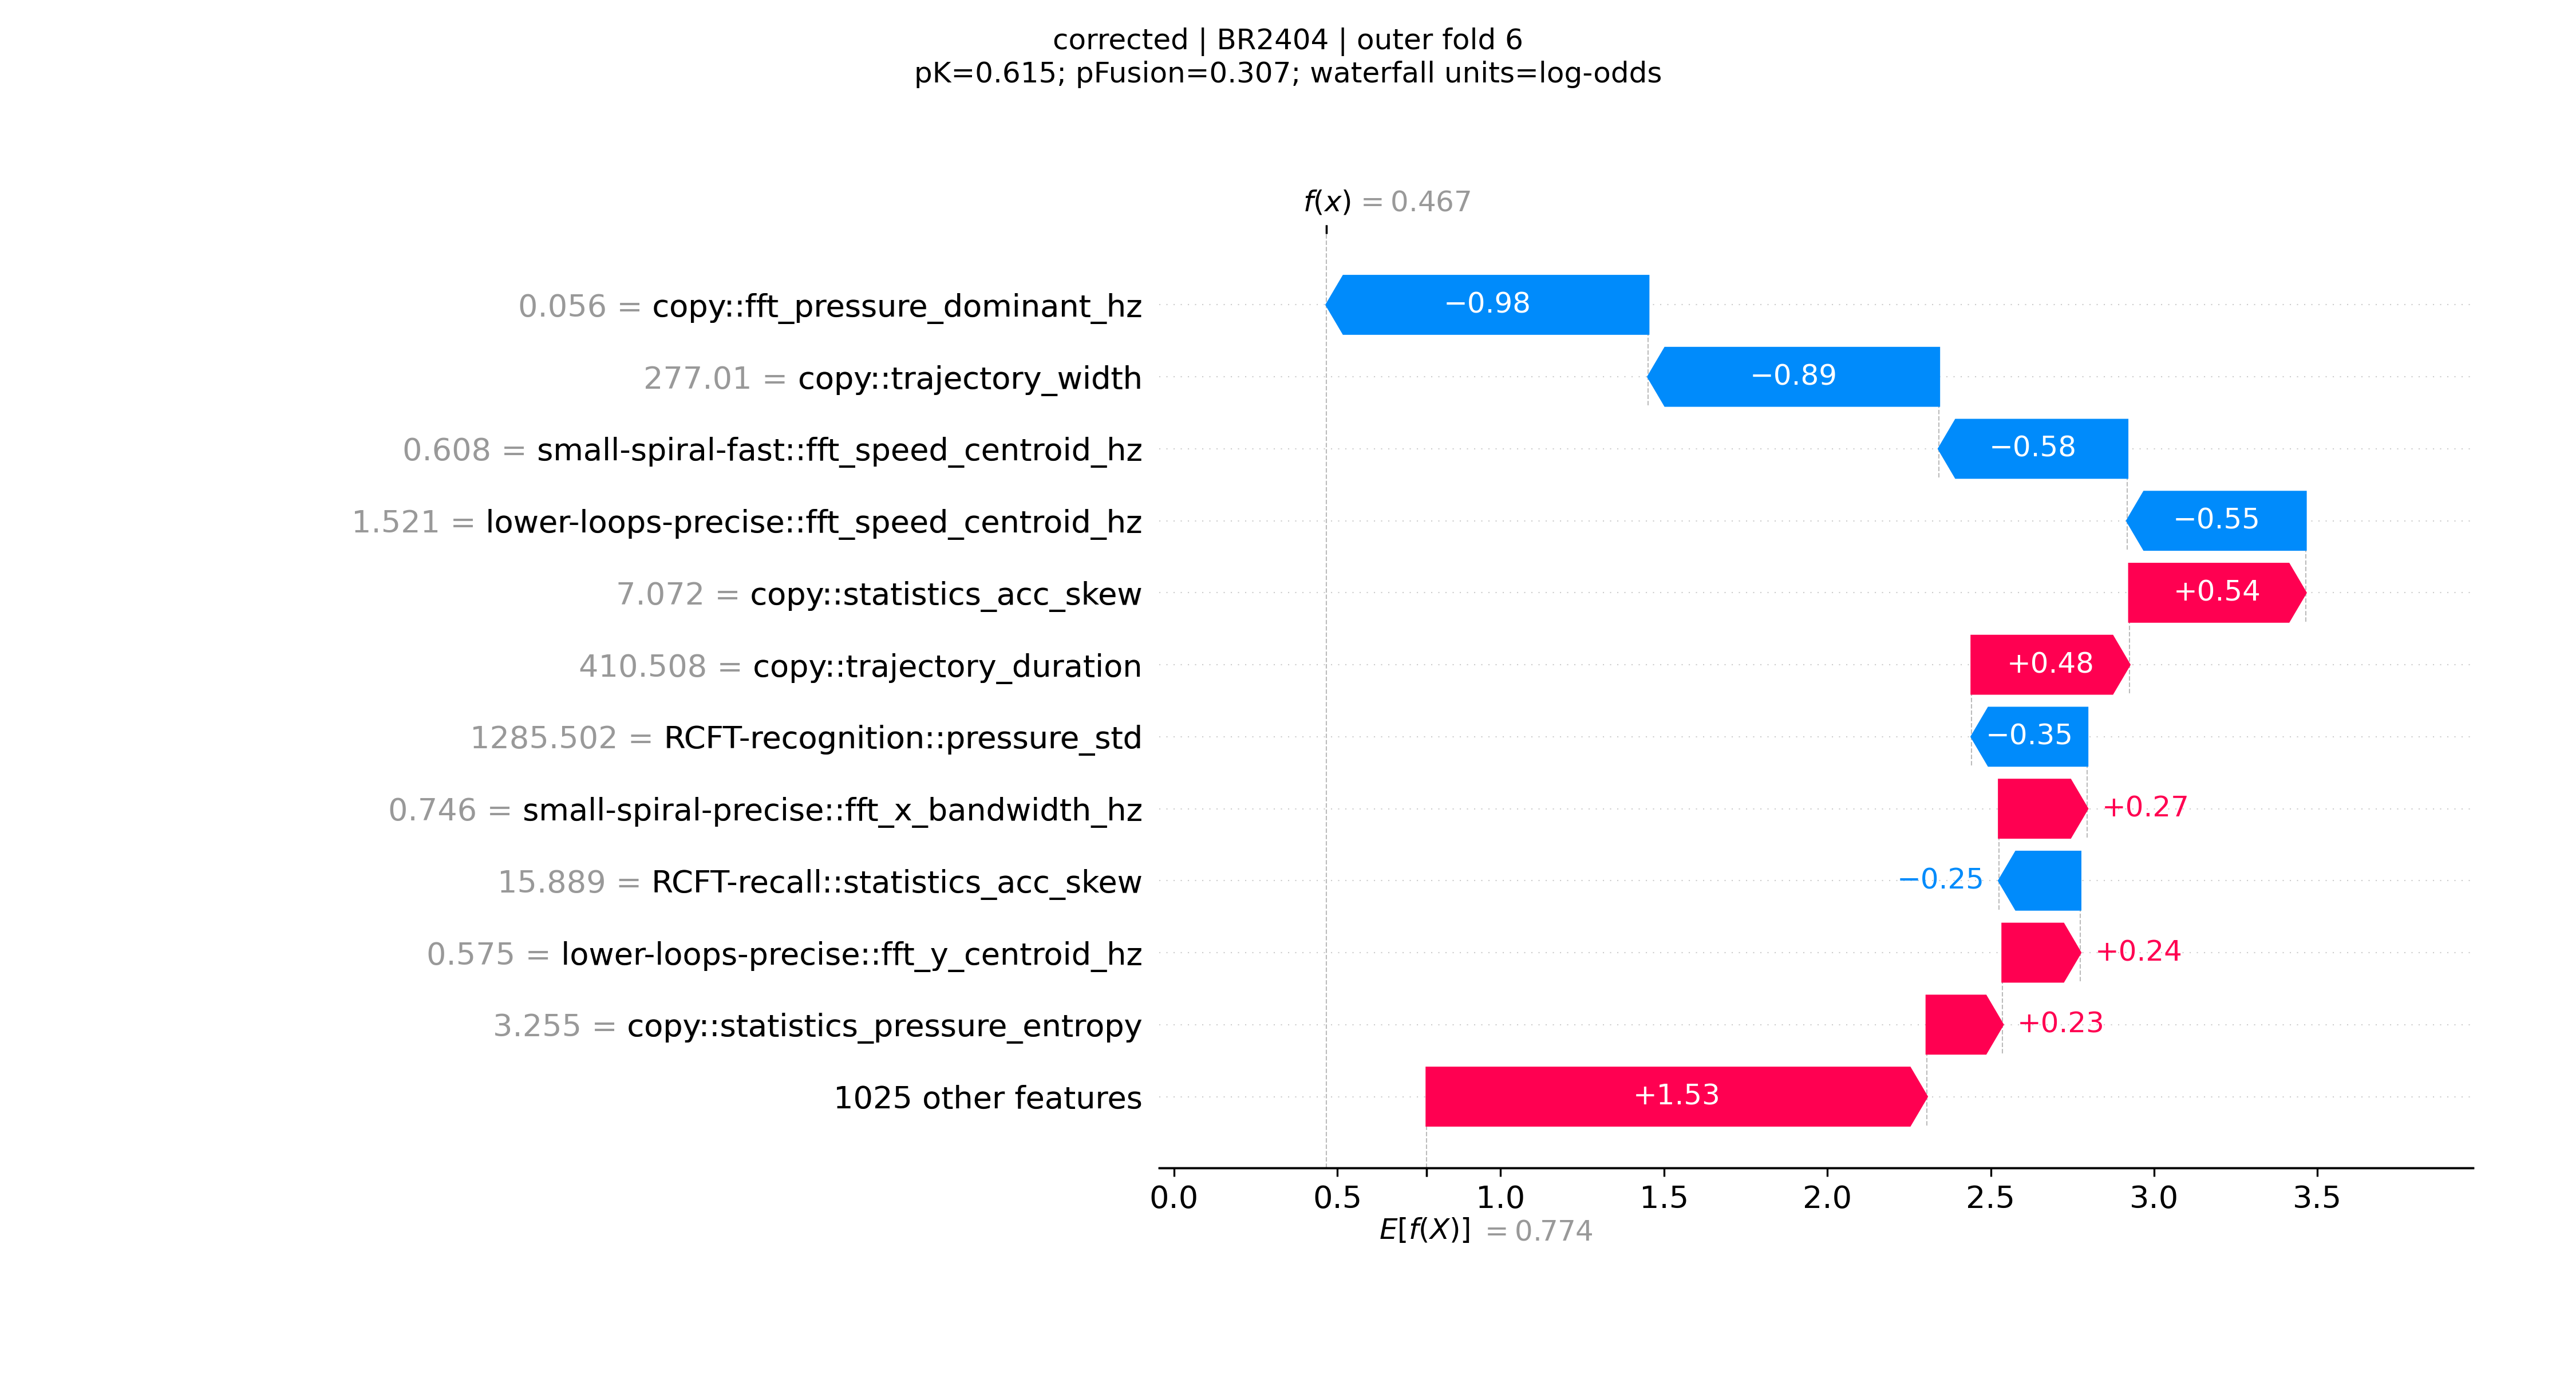

**waterfall_harmed** — First lexicographic participant in outcome; explanation of Kinematic, not feature SHAP of Fusion. Units: raw log-odds

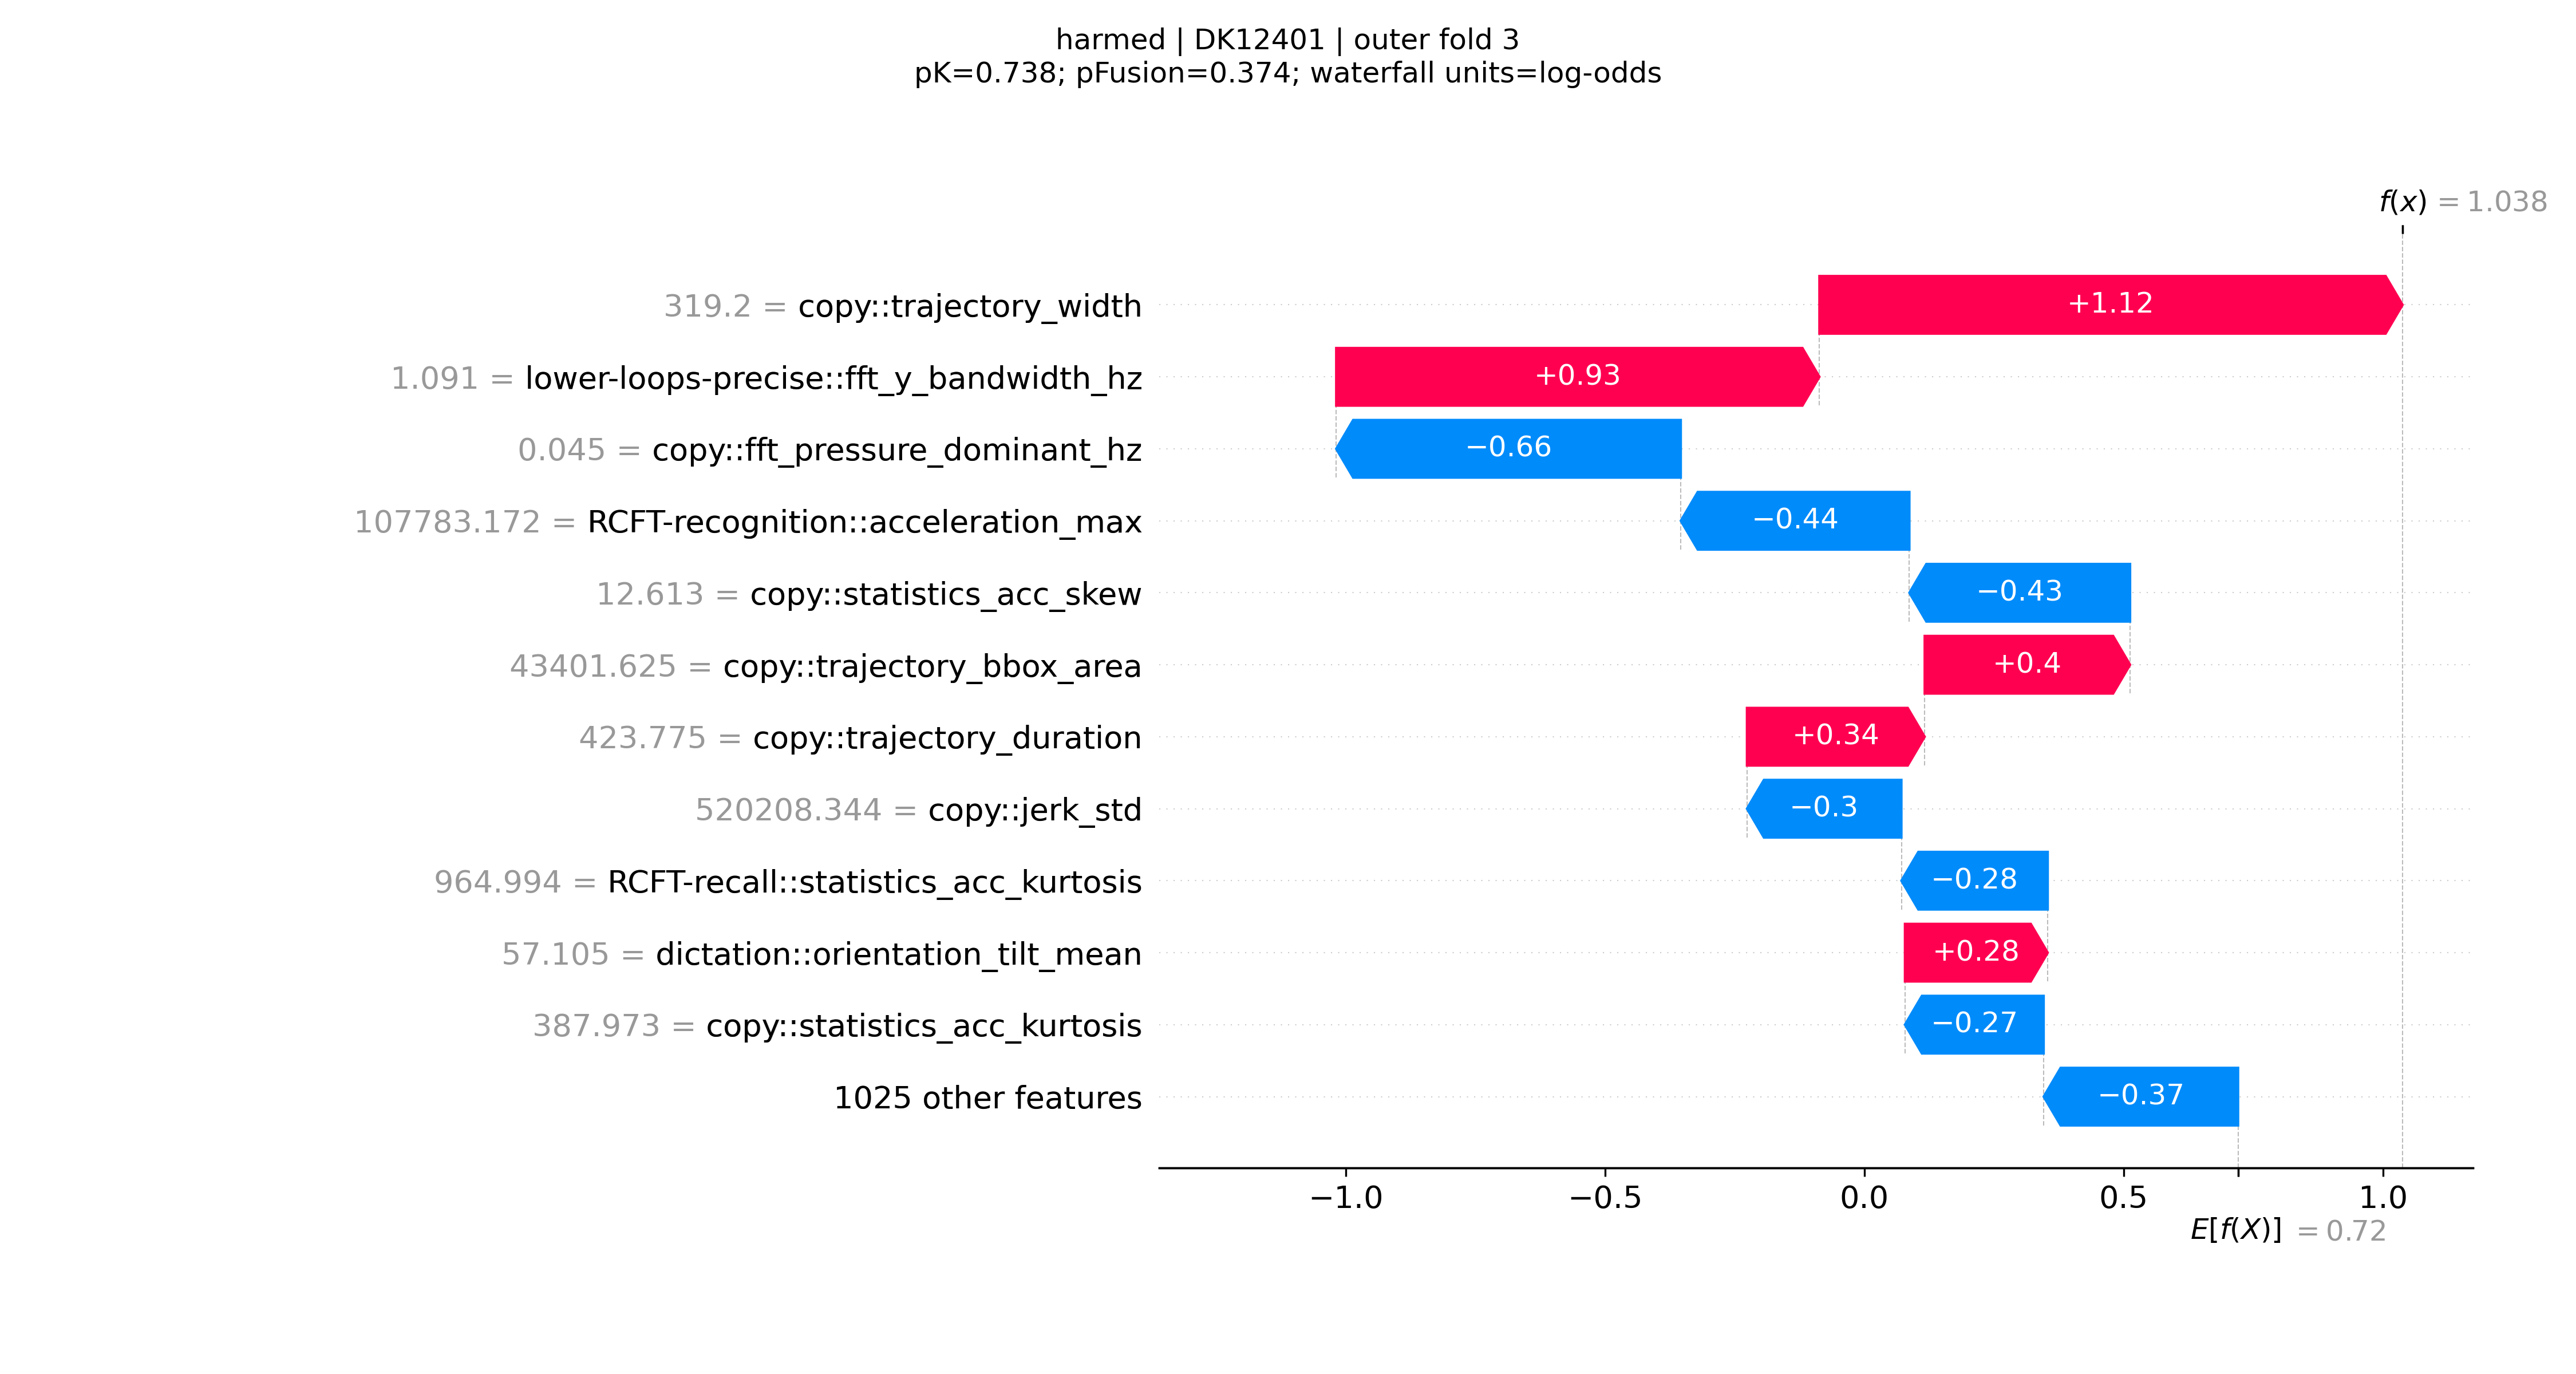

**waterfall_unchanged_correct** — First lexicographic participant in outcome; explanation of Kinematic, not feature SHAP of Fusion. Units: raw log-odds

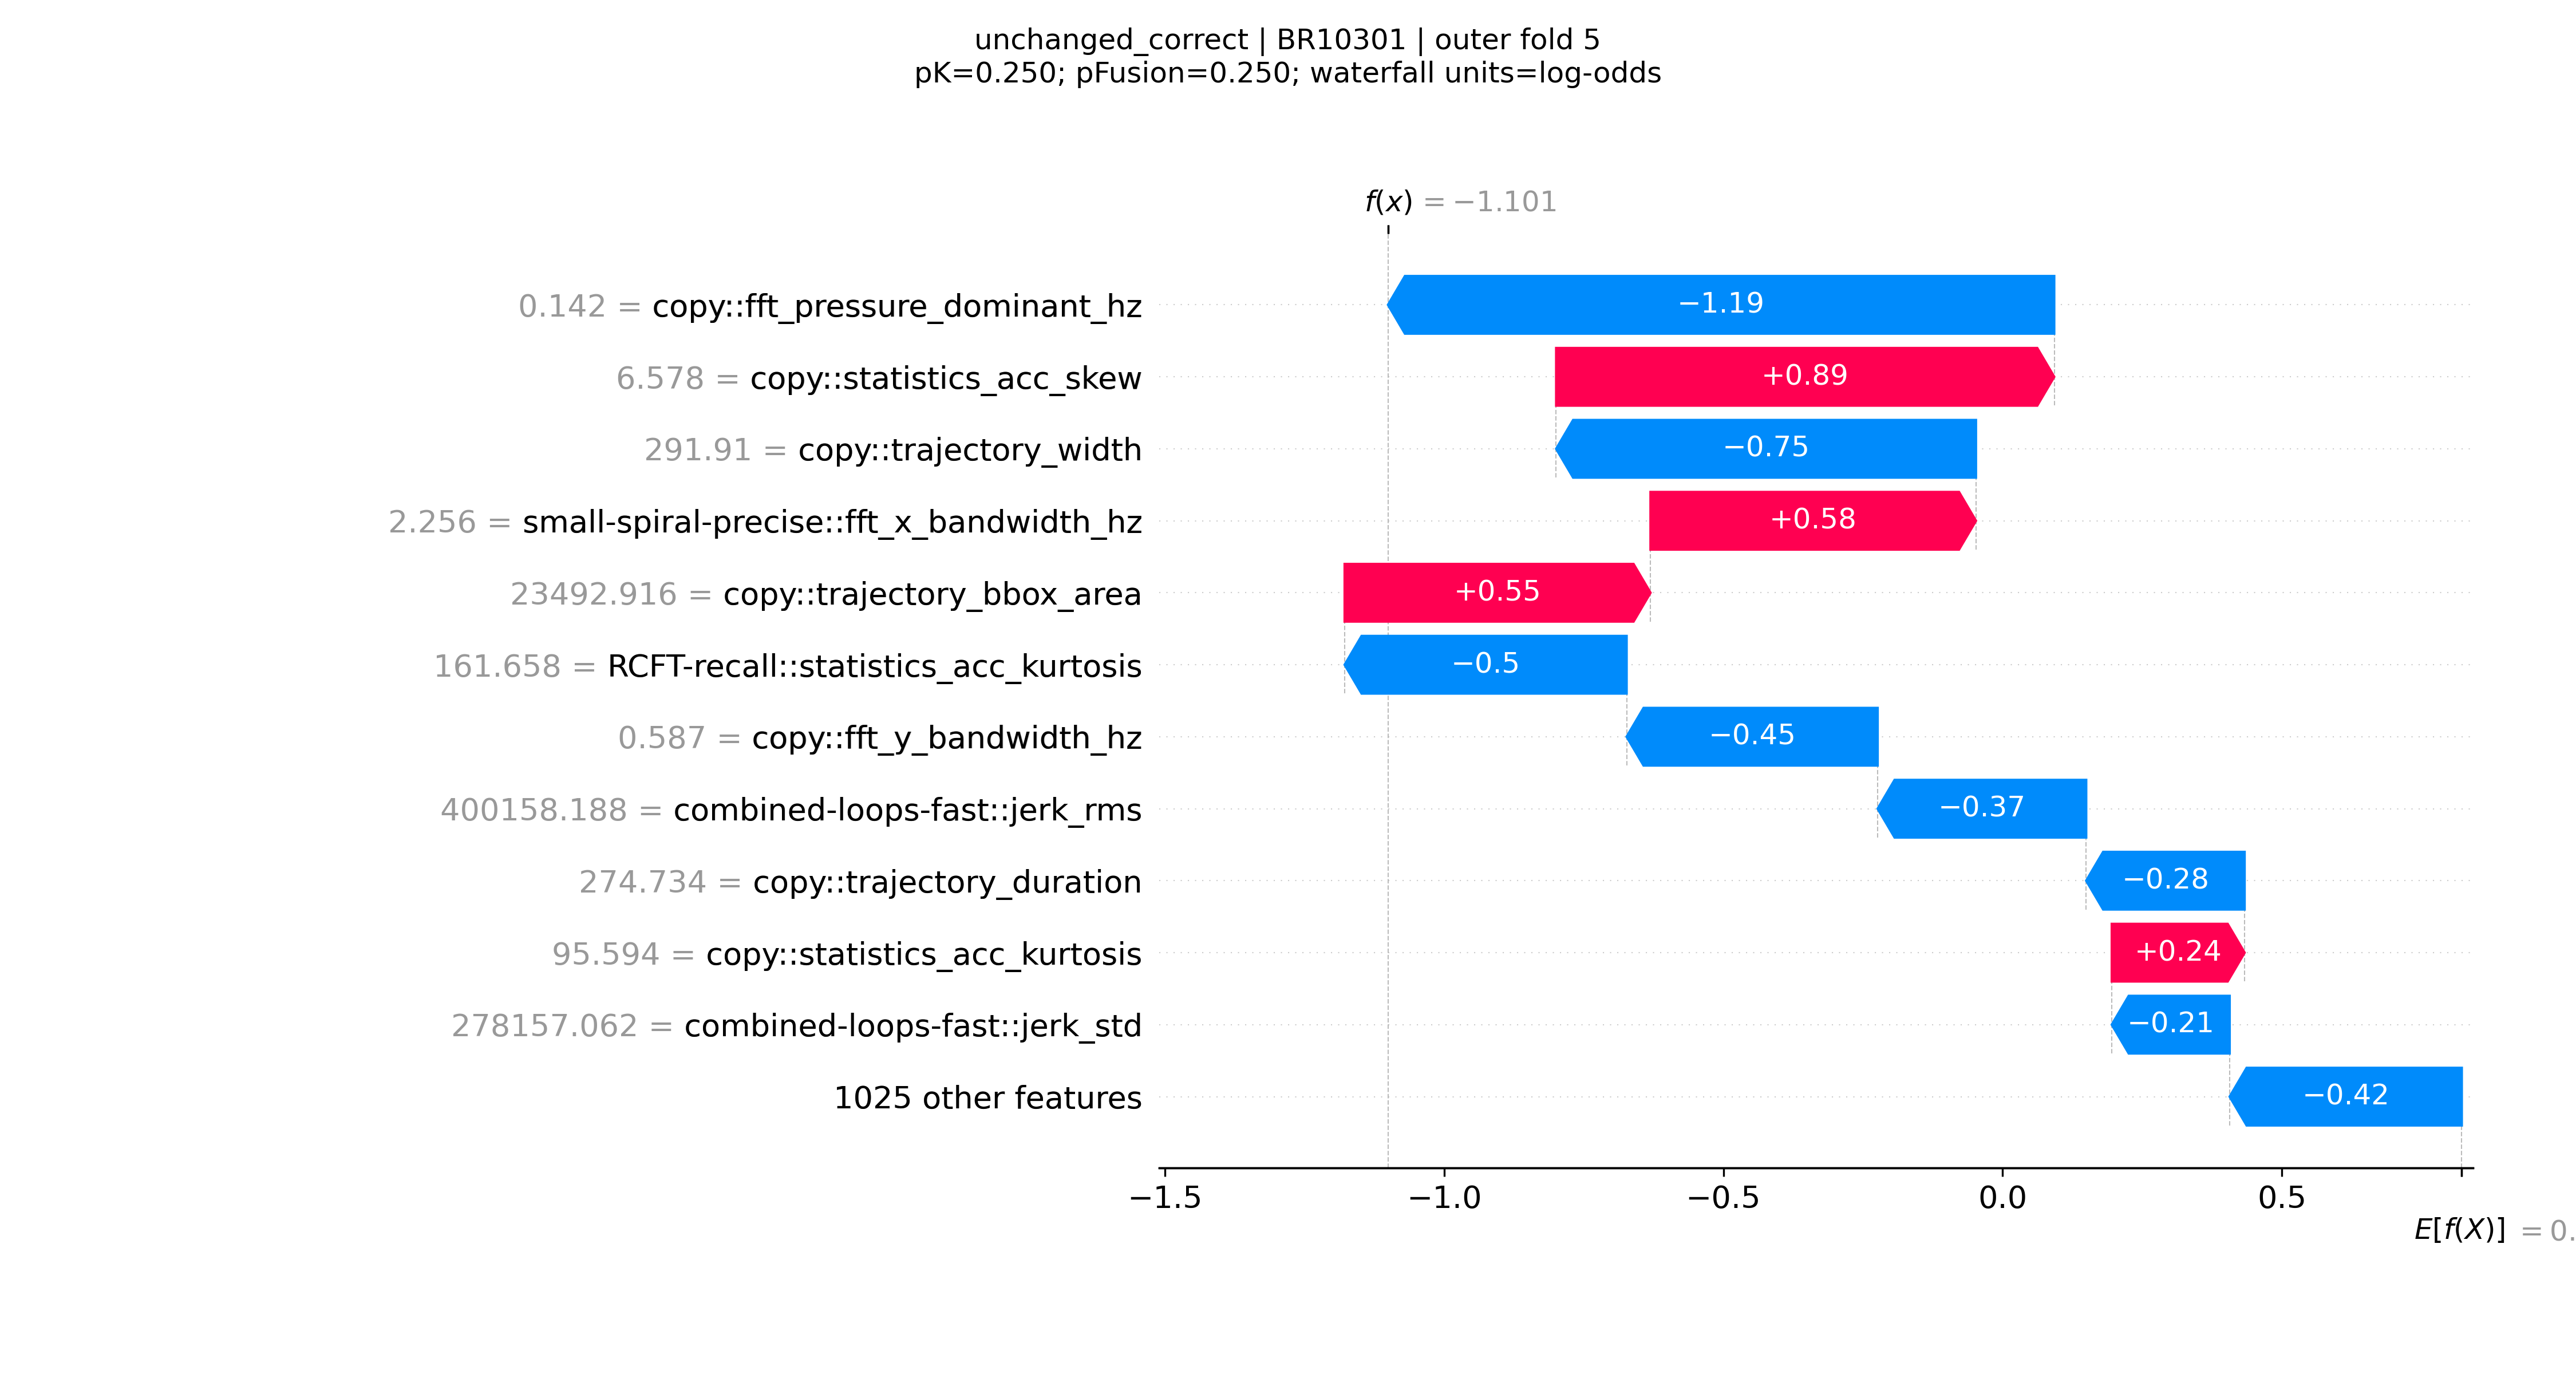

**waterfall_unchanged_wrong** — First lexicographic participant in outcome; explanation of Kinematic, not feature SHAP of Fusion. Units: raw log-odds

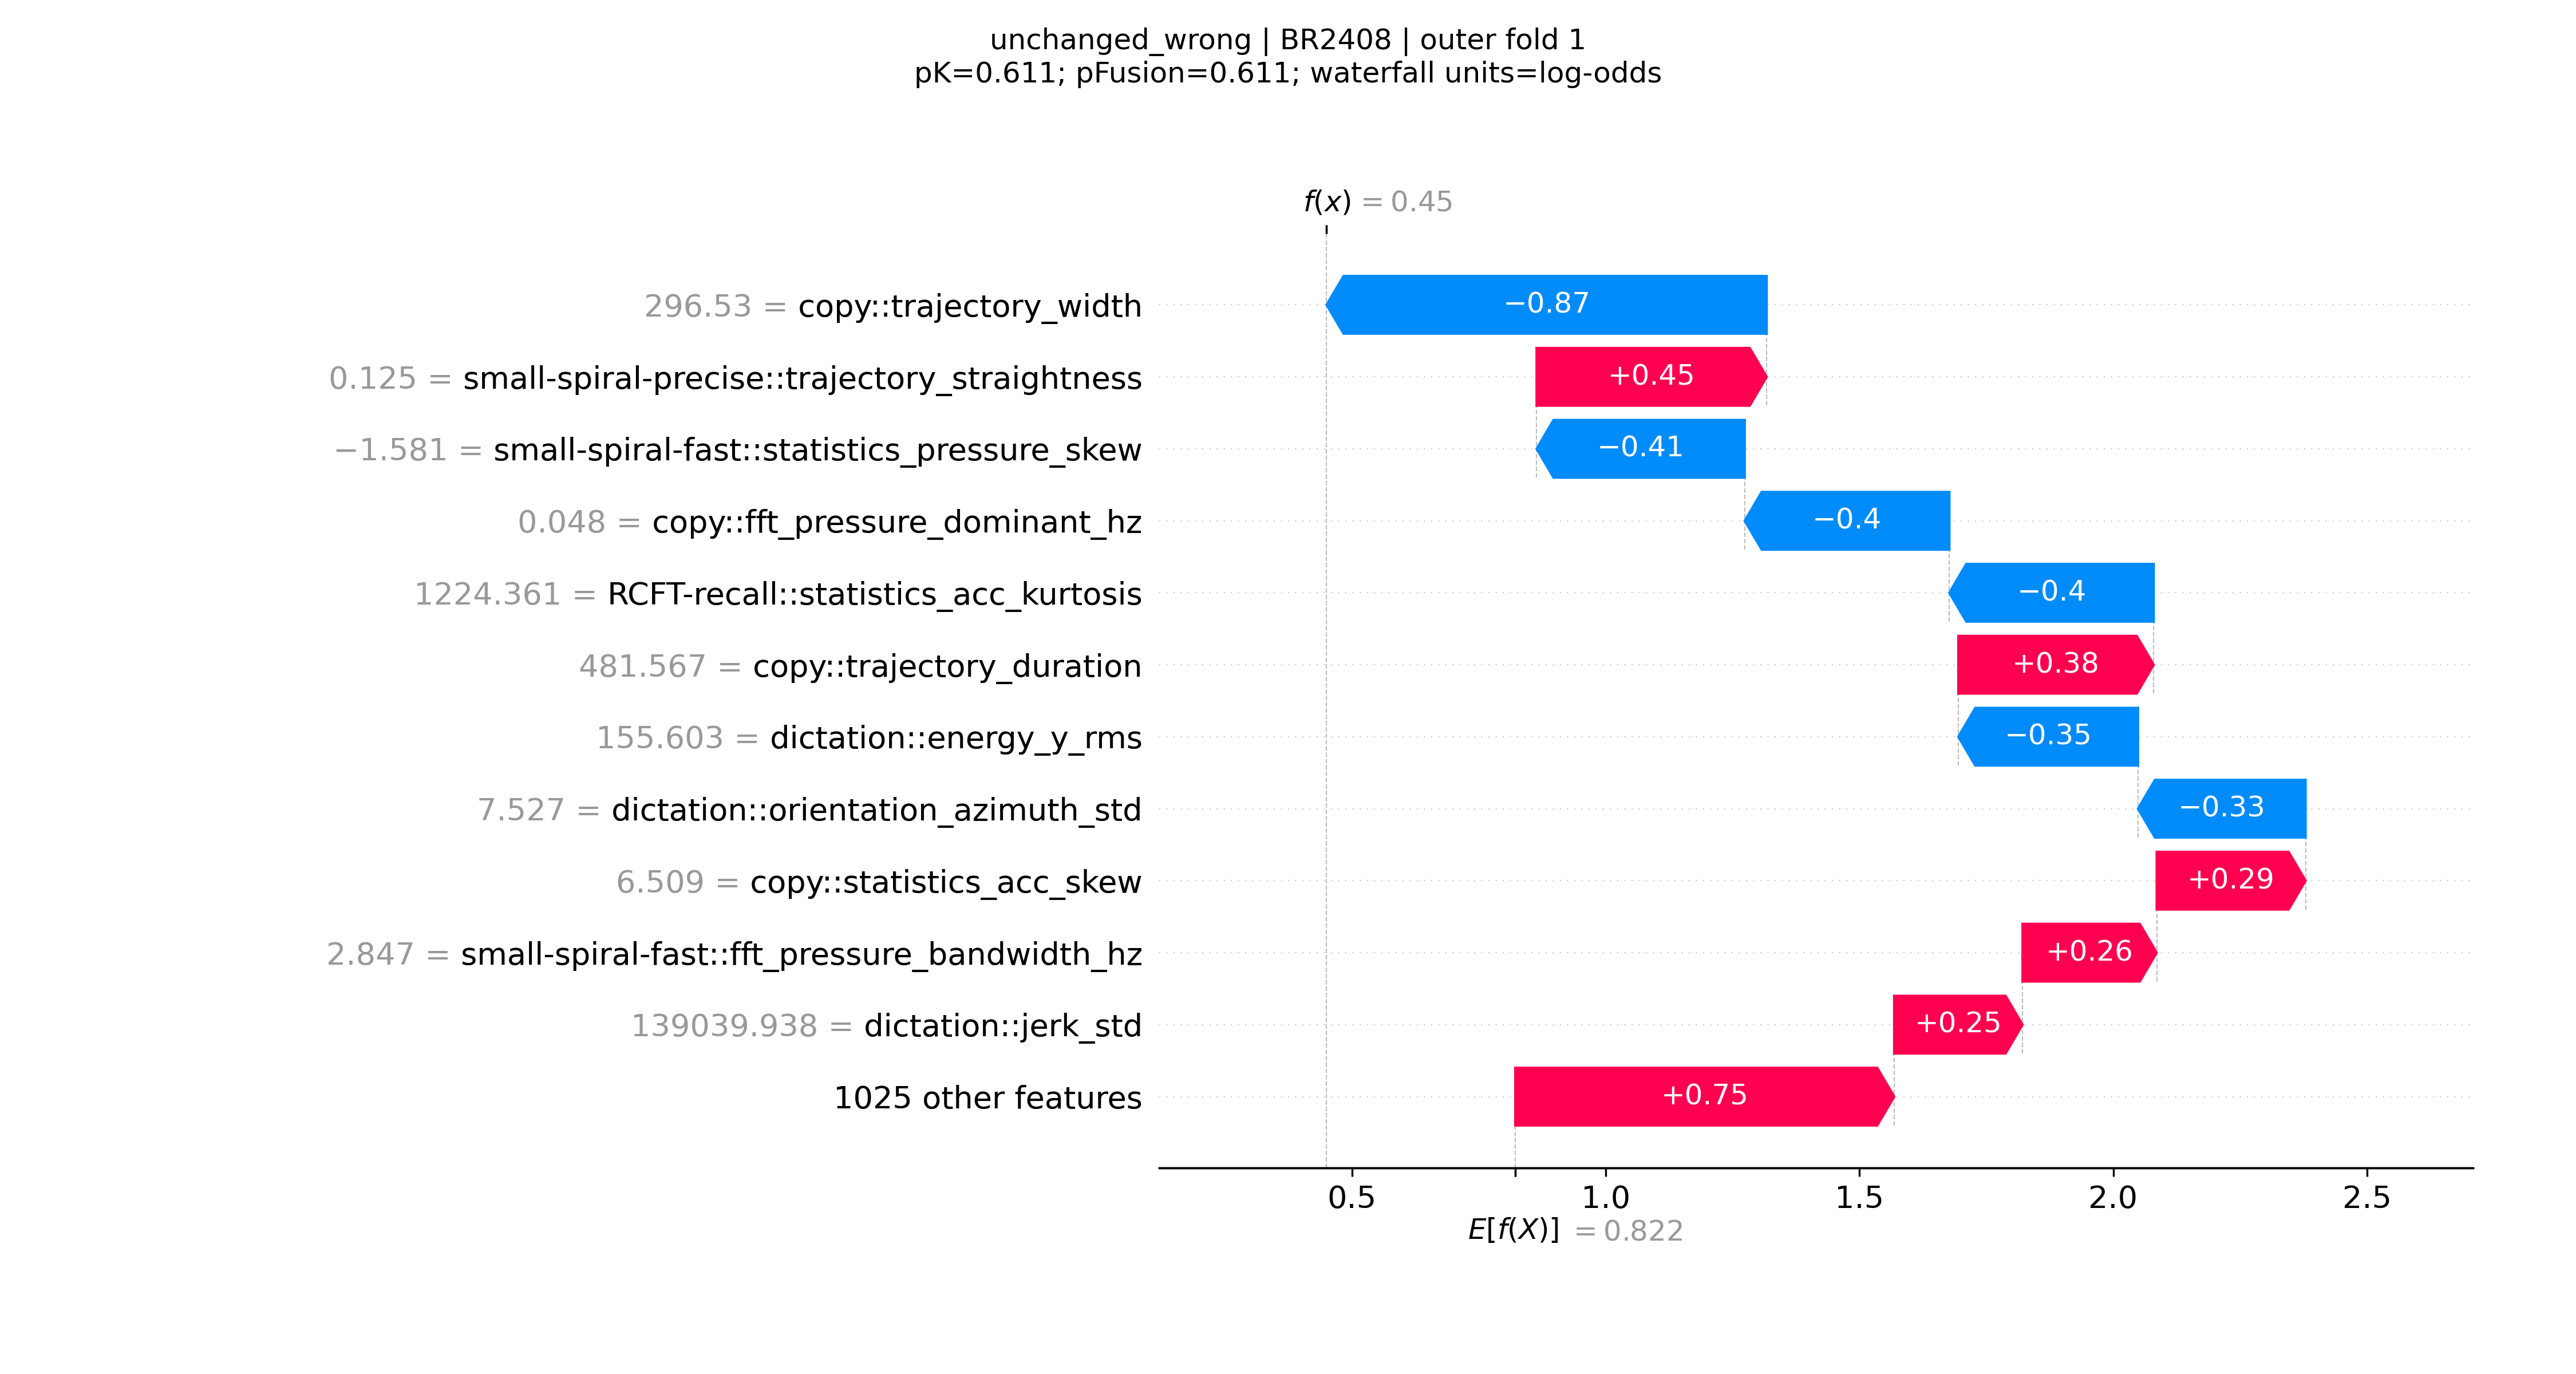

**task_waterfall** — Task sums reconstruct margin, unlike global absolute attribution mass. Units: signed raw log-odds

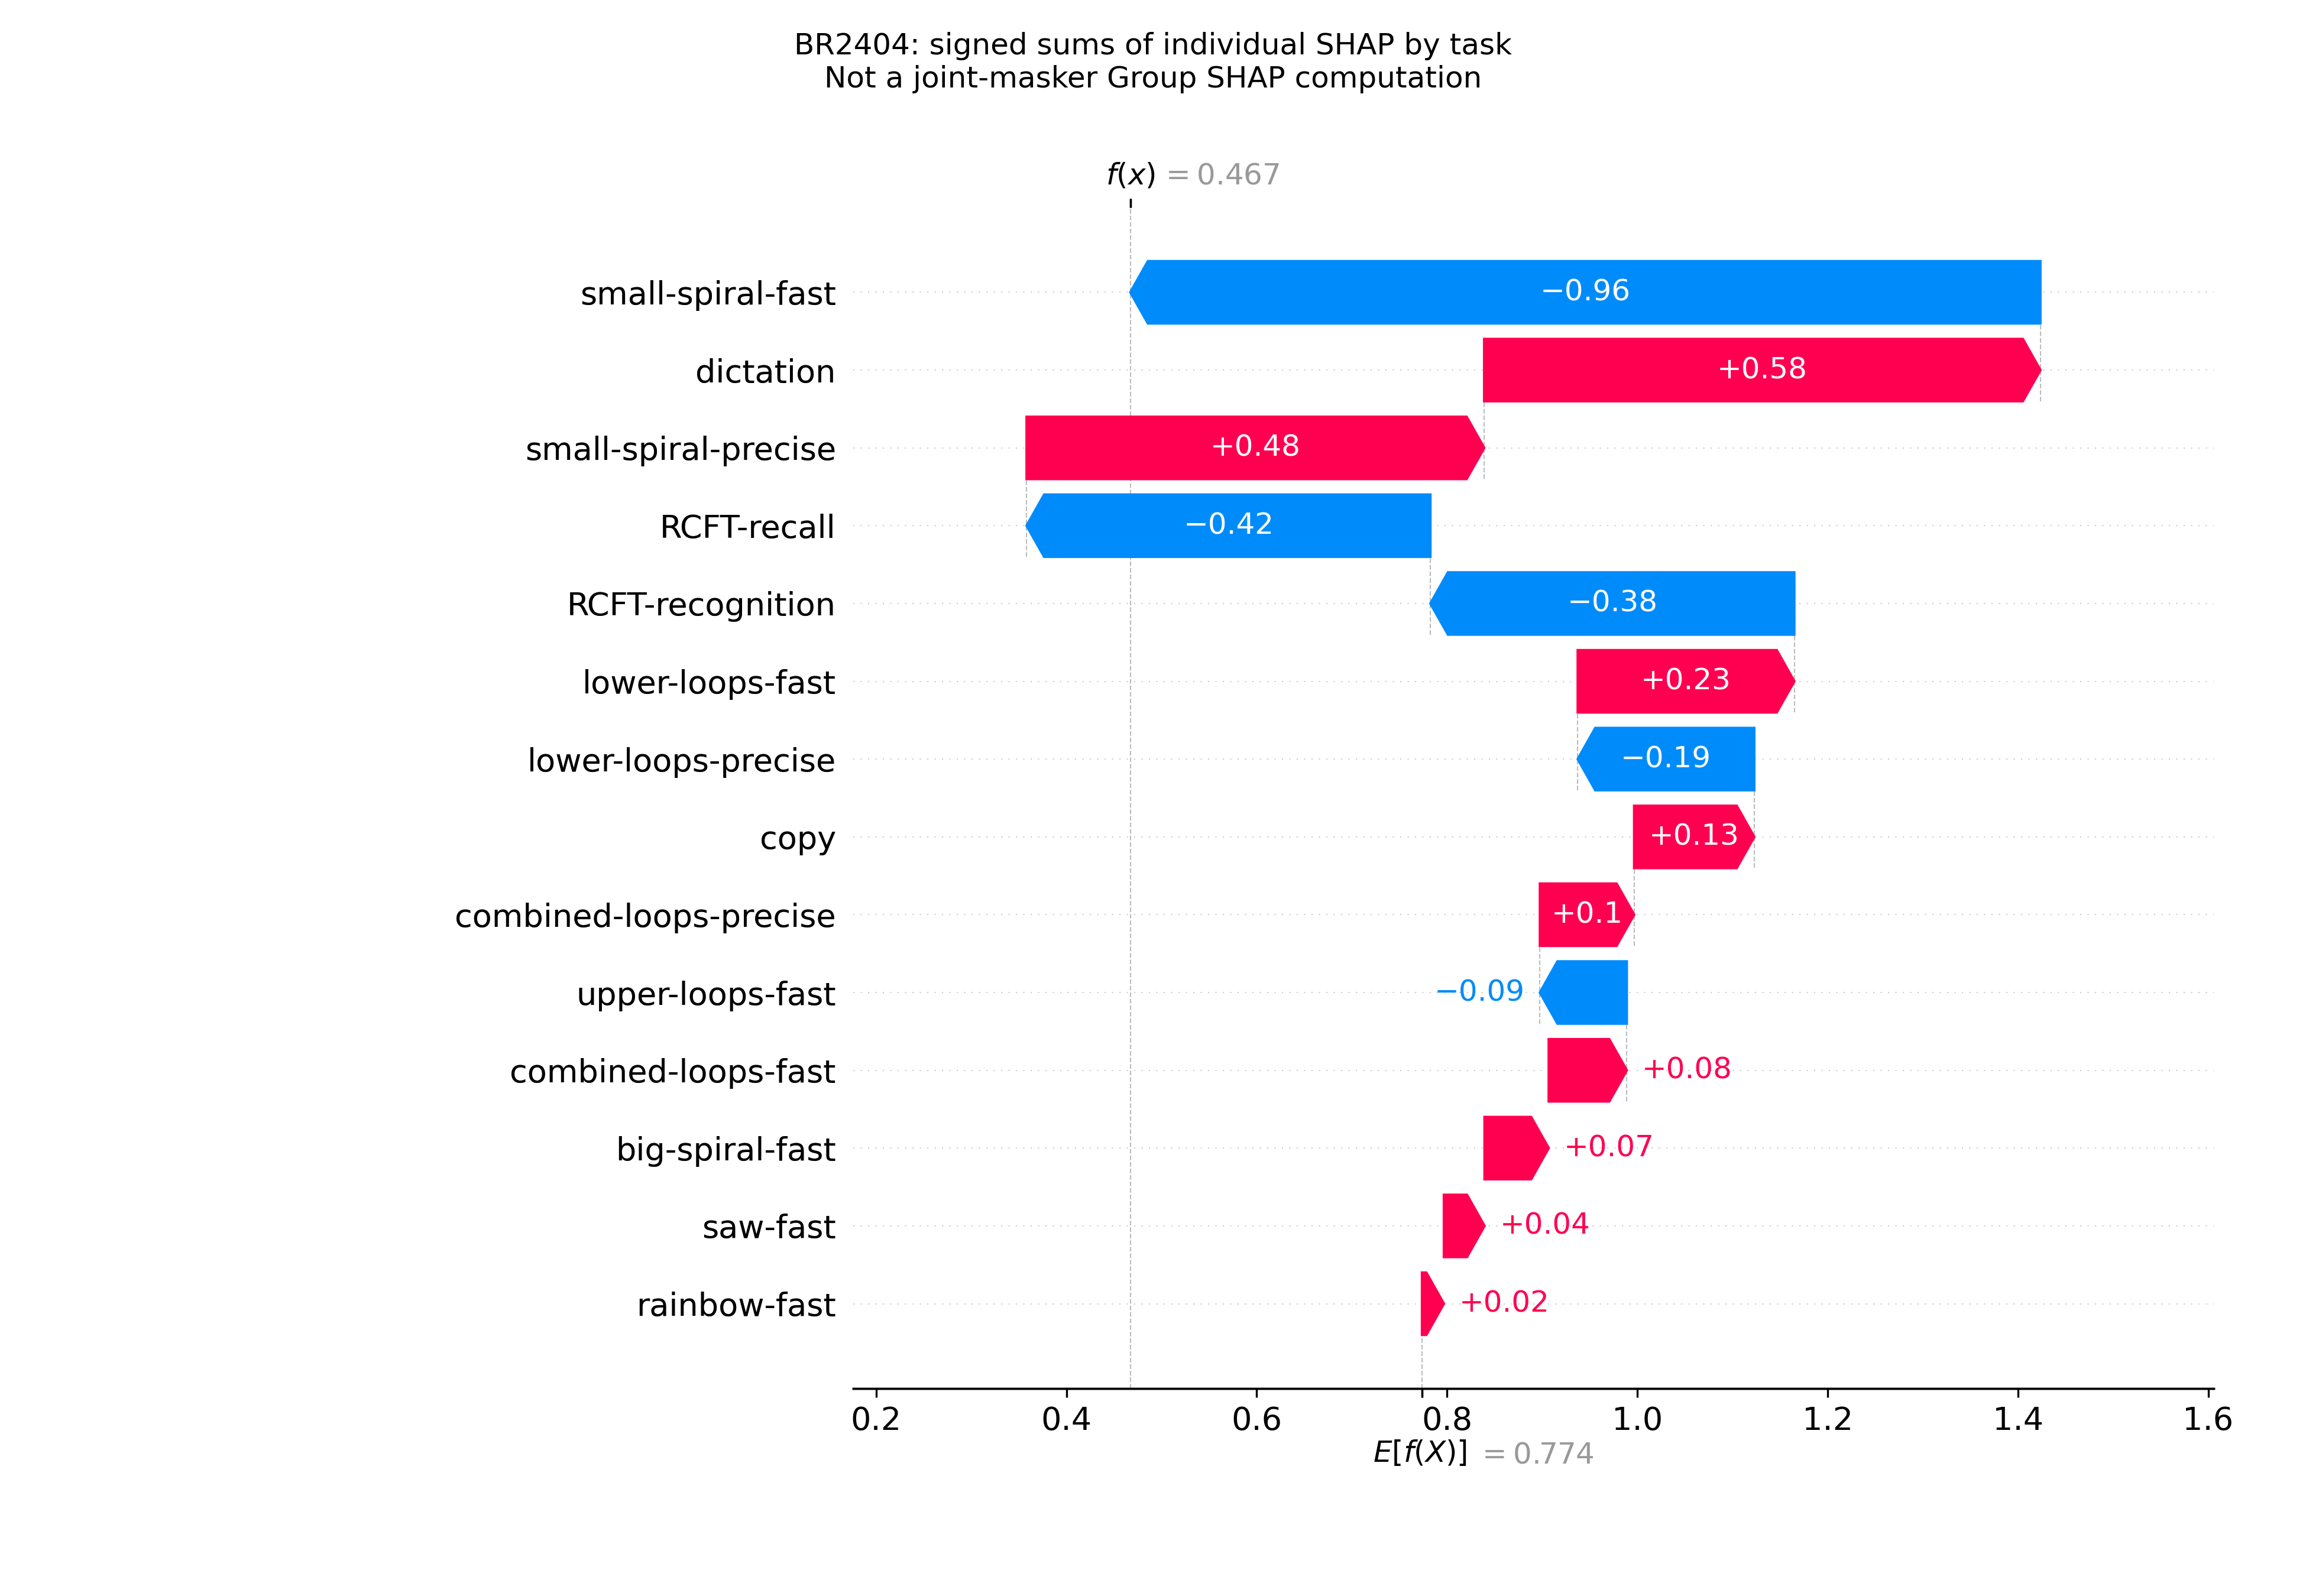

In [11]:
display(pd.DataFrame(json.loads((OUT/'local_cases.json').read_text())))
show_figures(['waterfall_corrected','waterfall_harmed','waterfall_unchanged_correct','waterfall_unchanged_wrong','task_waterfall'])

## Task/group importance và stability

**task_importance** — Each task has 74 features; six-fold SD is not a confidence interval. Units: mean absolute log-odds mass

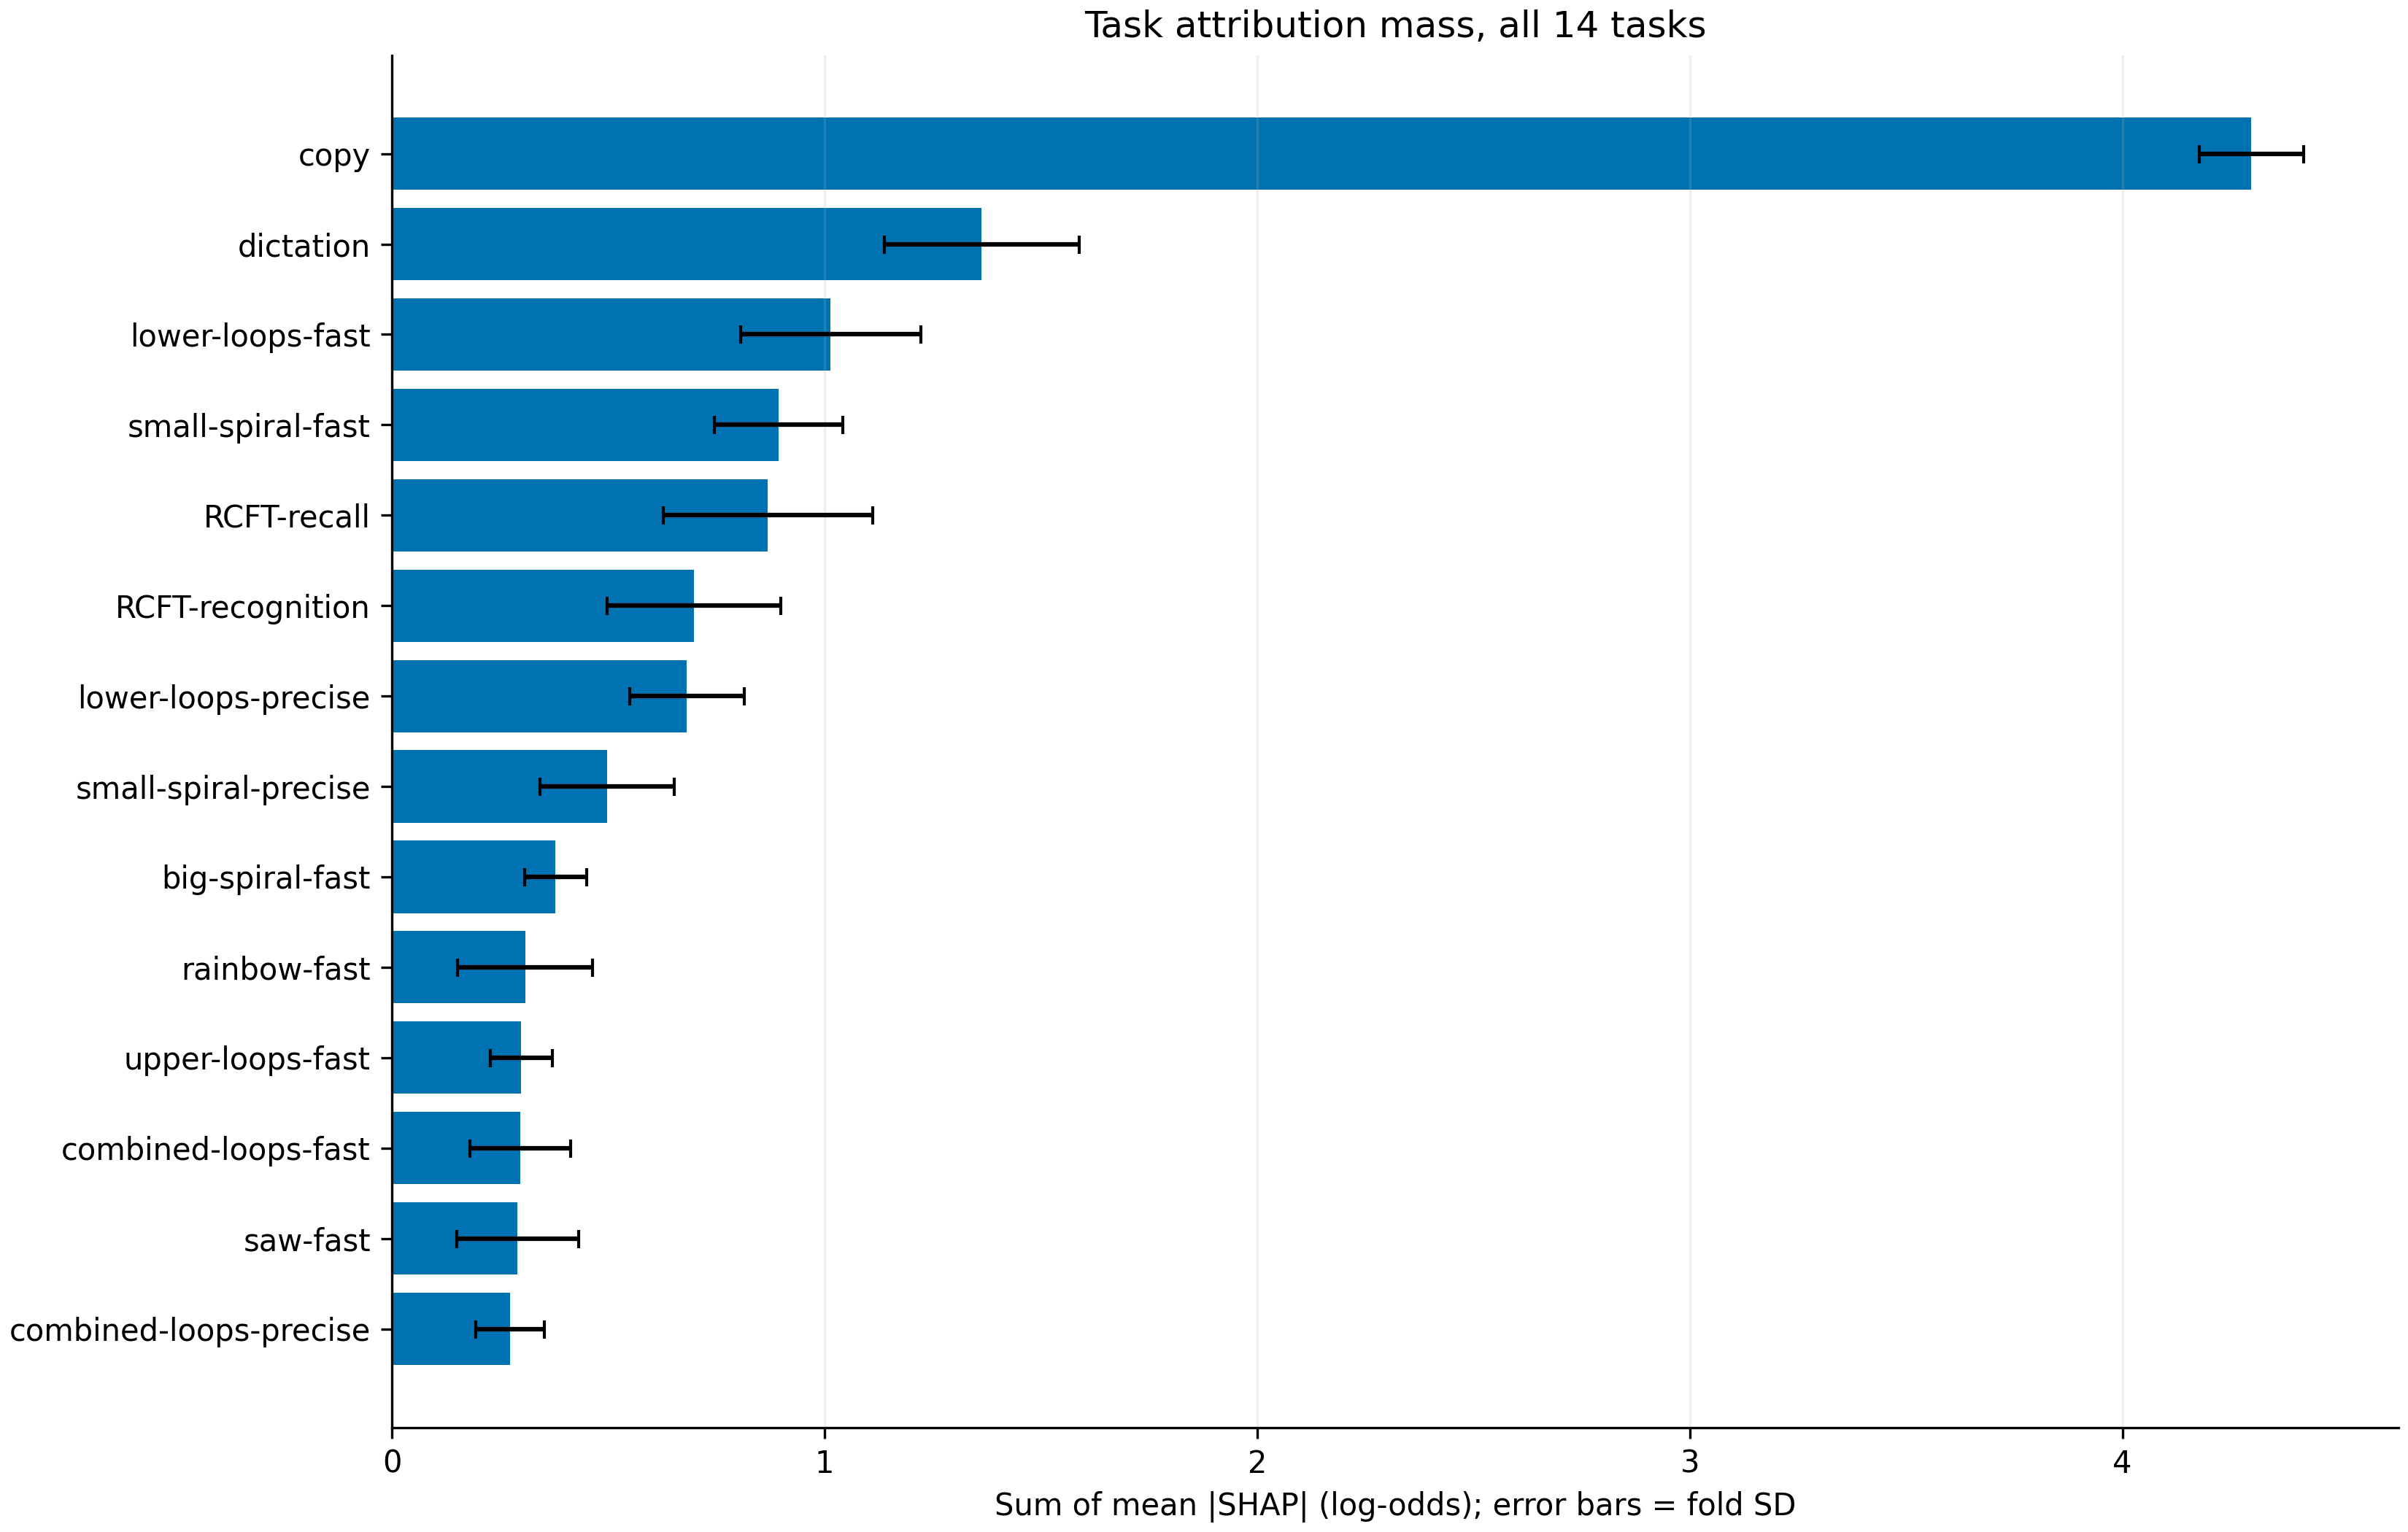

**feature_groups** — Source-prefix groups; compare total and per-feature average to expose count effects. Units: log-odds mass or mean per feature

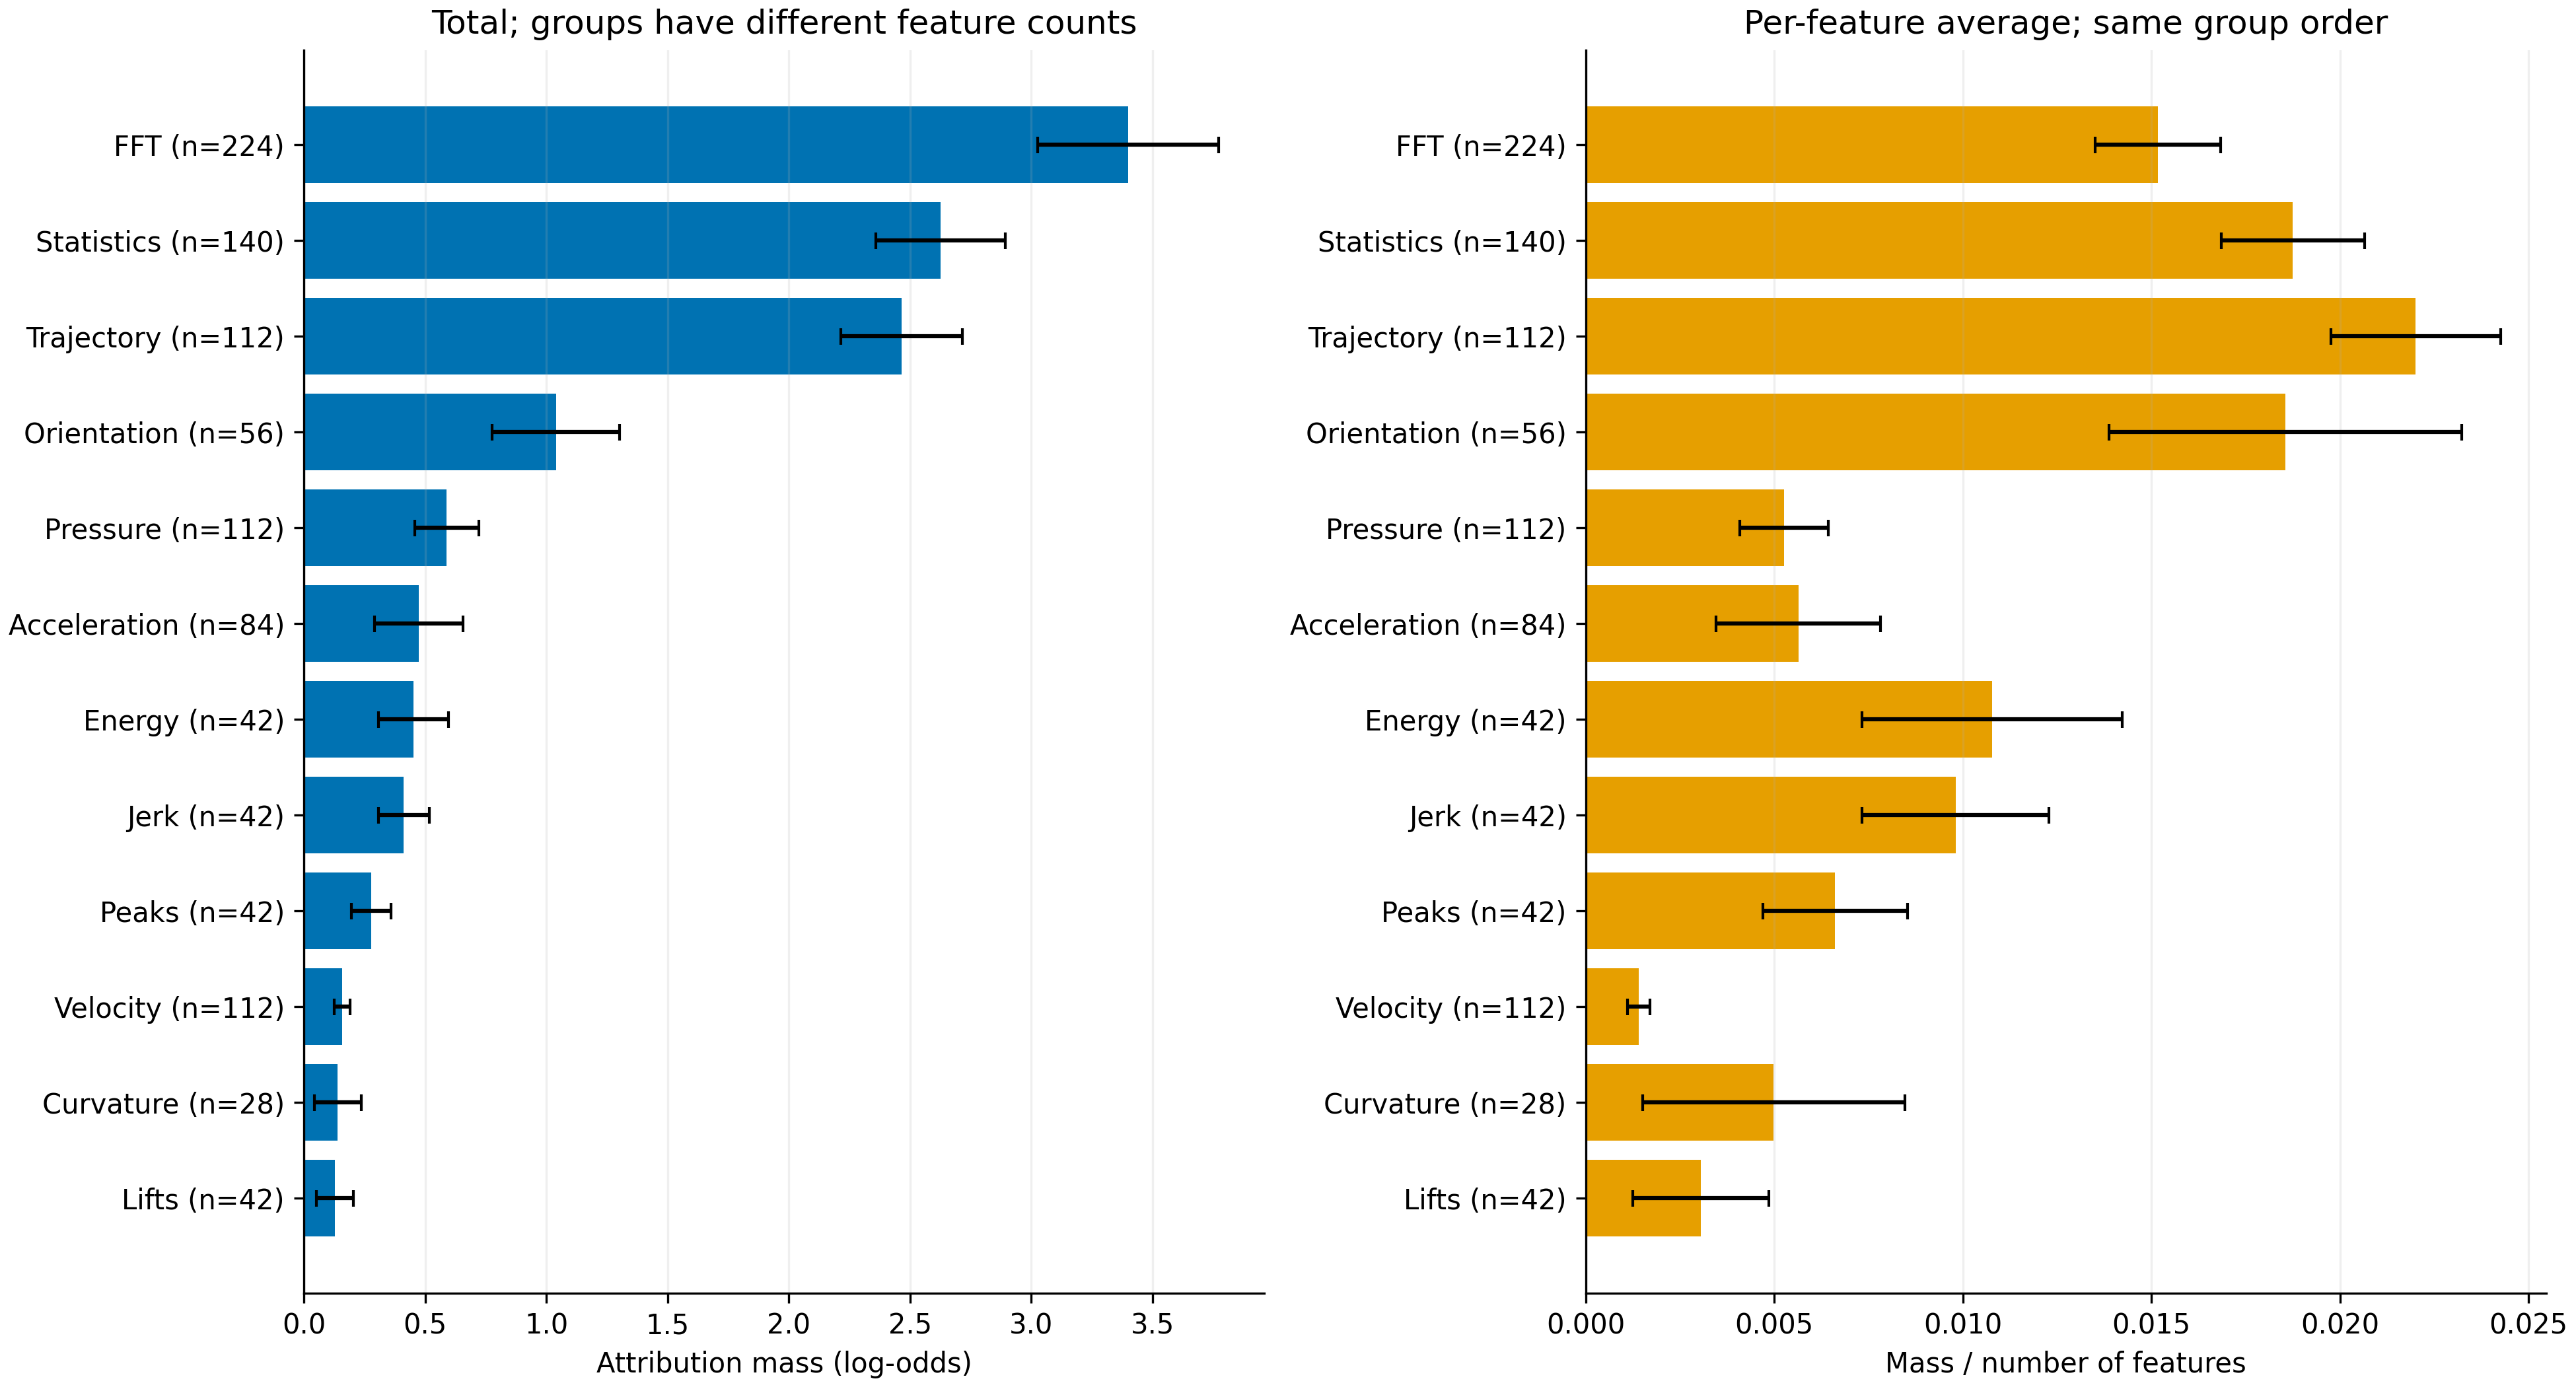

**task_group_heatmap** — All task/group cells, no omission of low attribution cells. Units: mean absolute log-odds mass

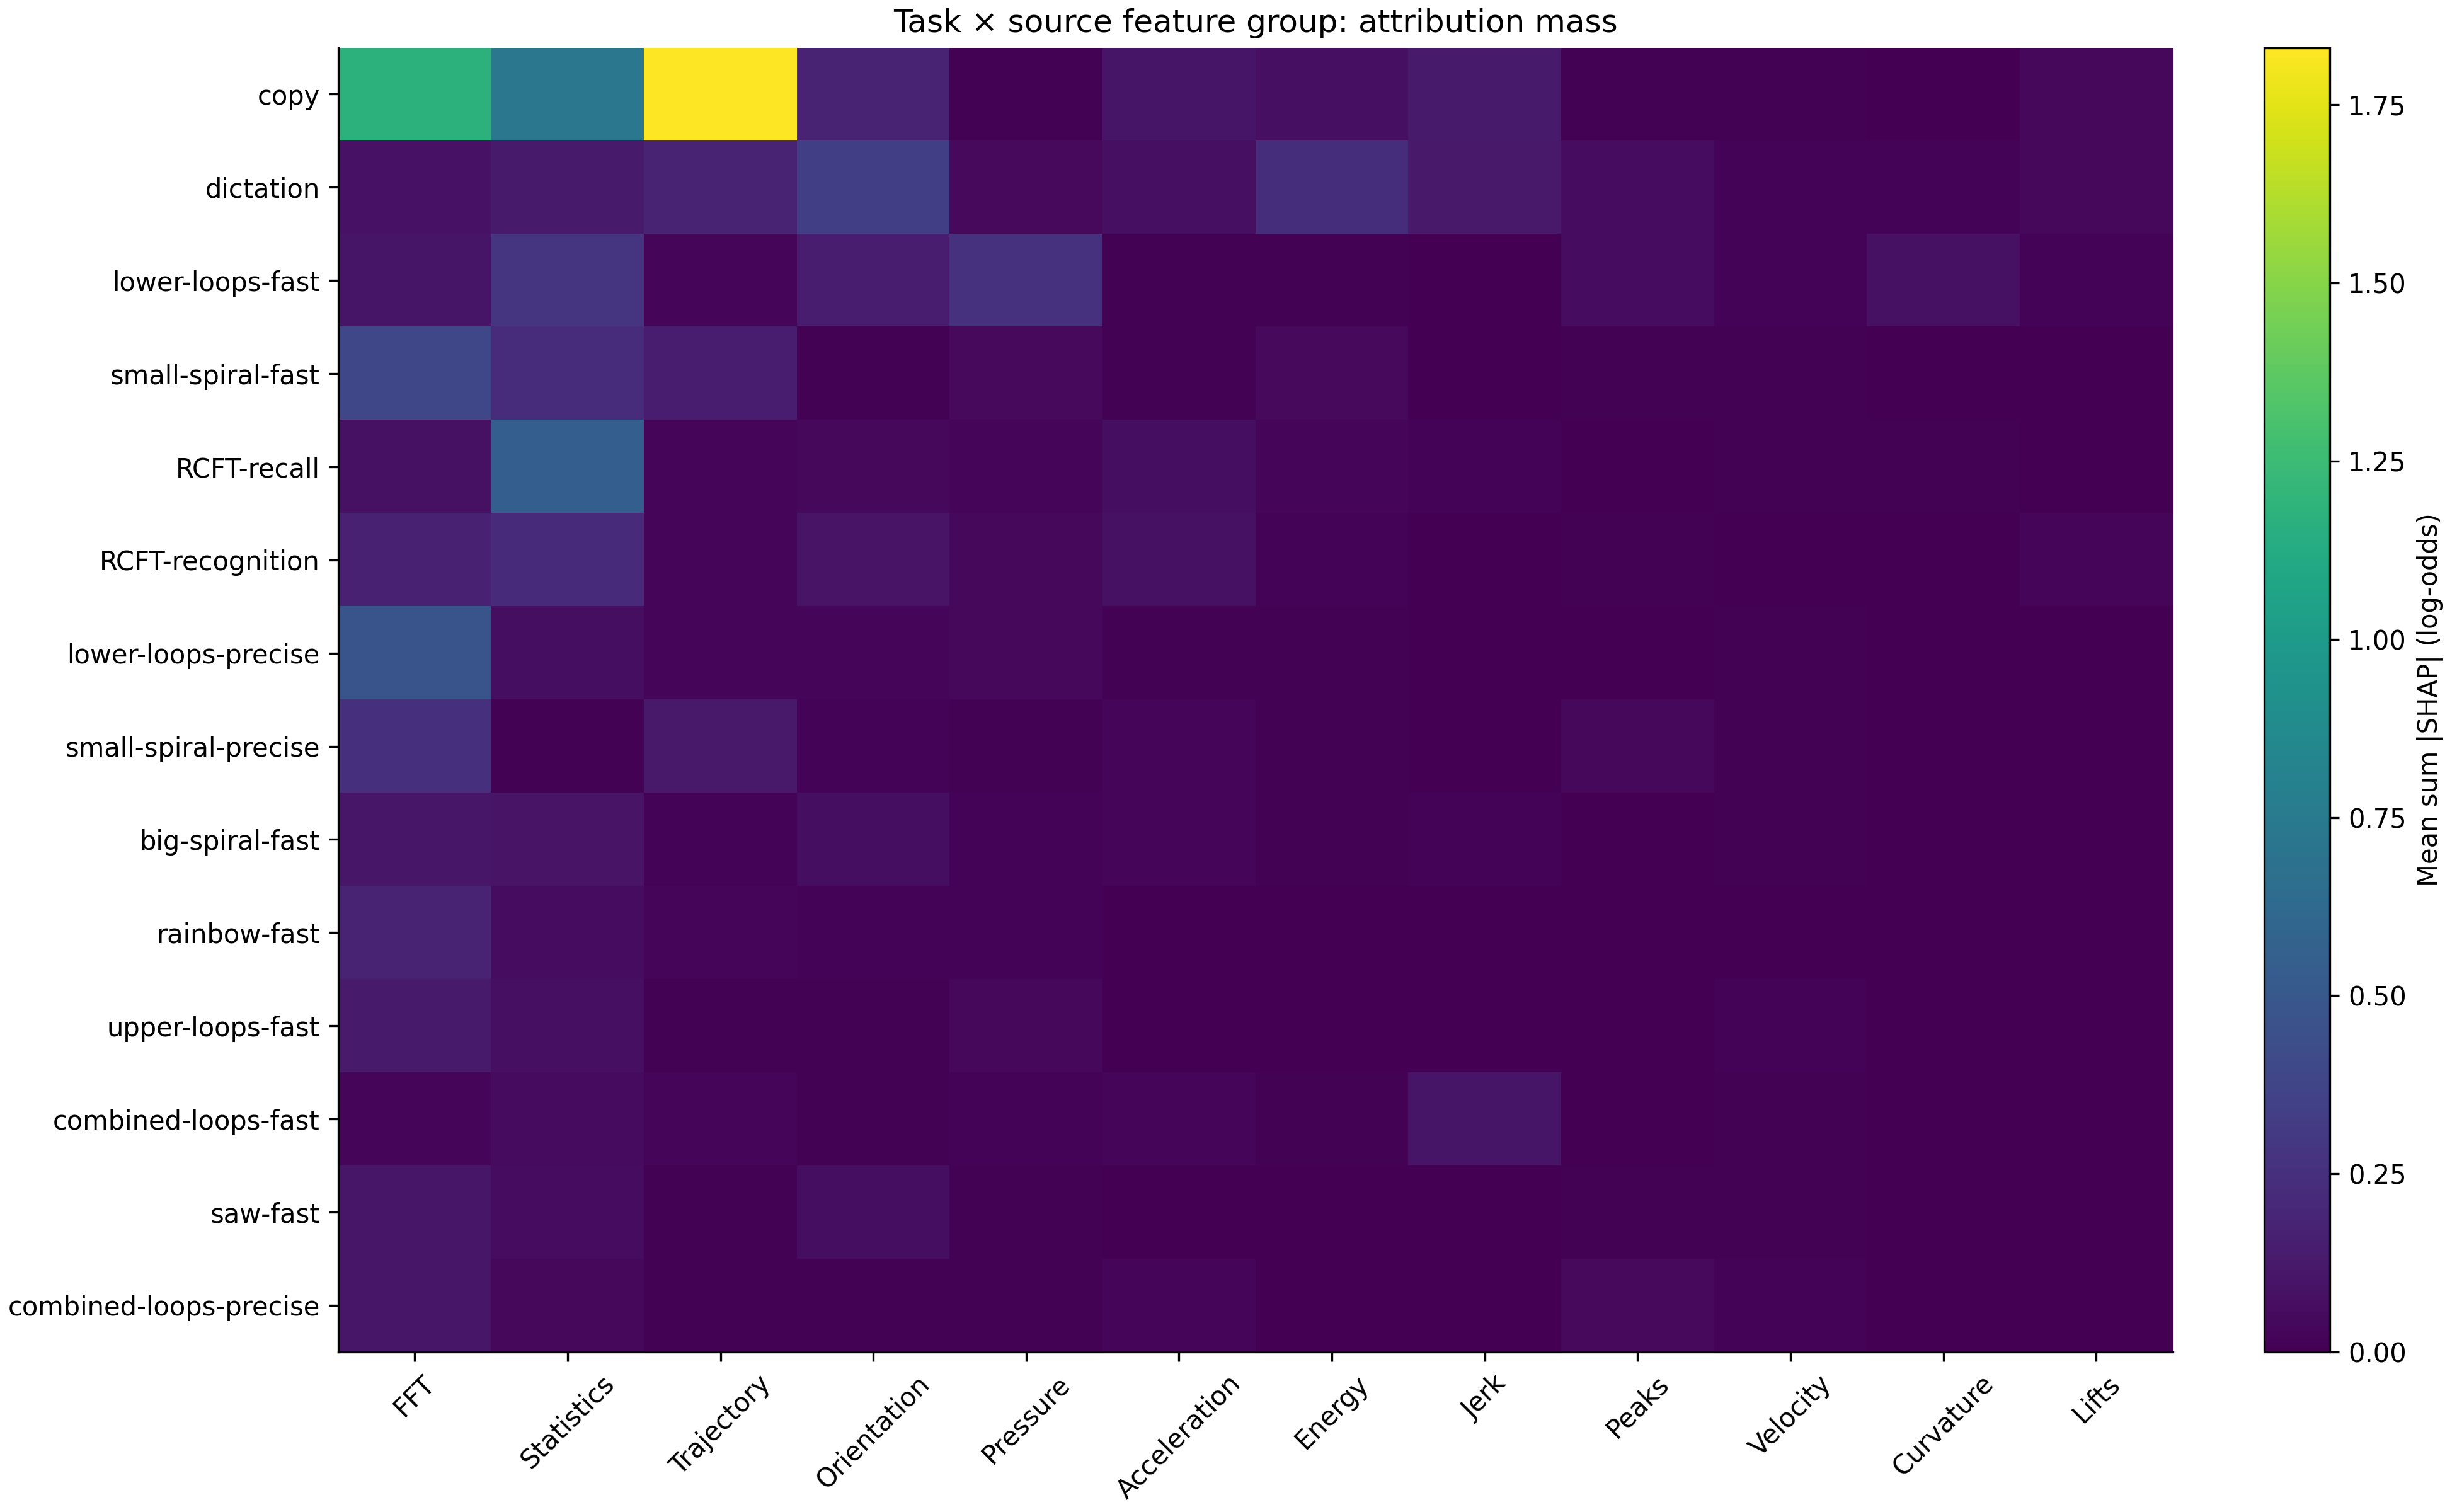

**task_fold_ranks** — Six models/test samples; dependent training folds, not independent replications. Units: rank

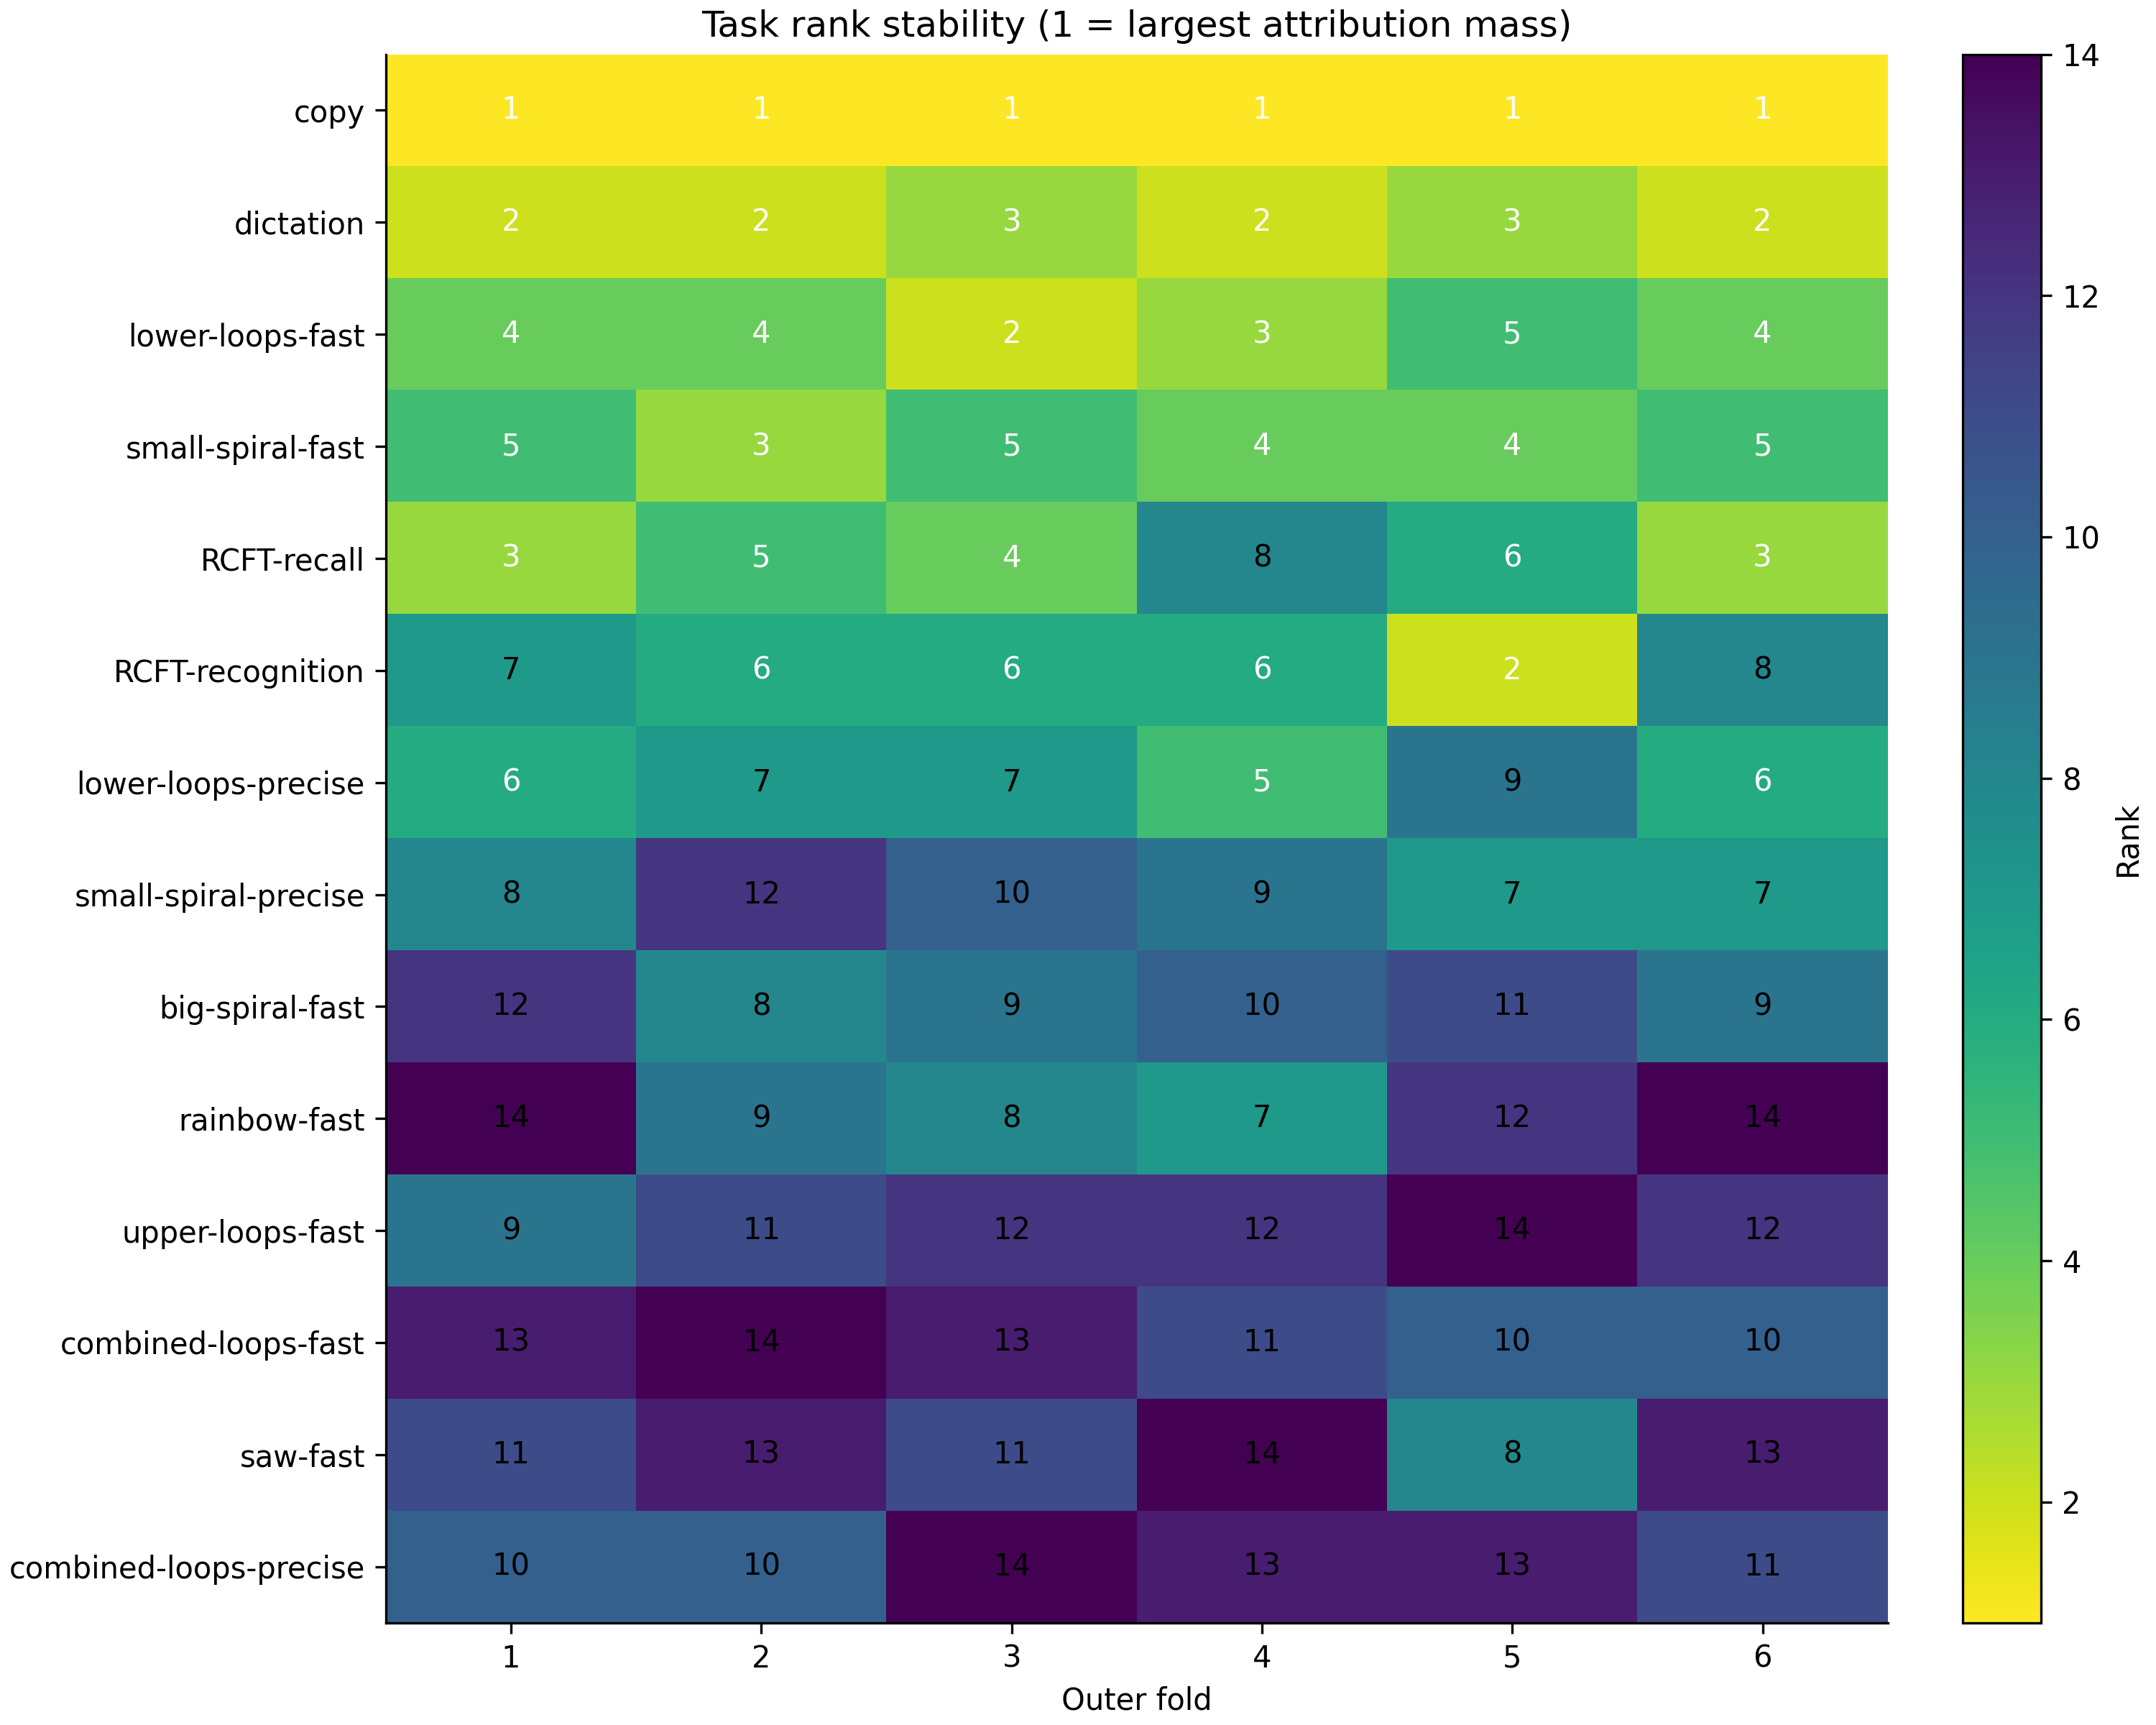

**grouped_permutation_tasks** — All task blocks ordered by SHAP mass; retain negative score drops. Units: F1 macro percentage points

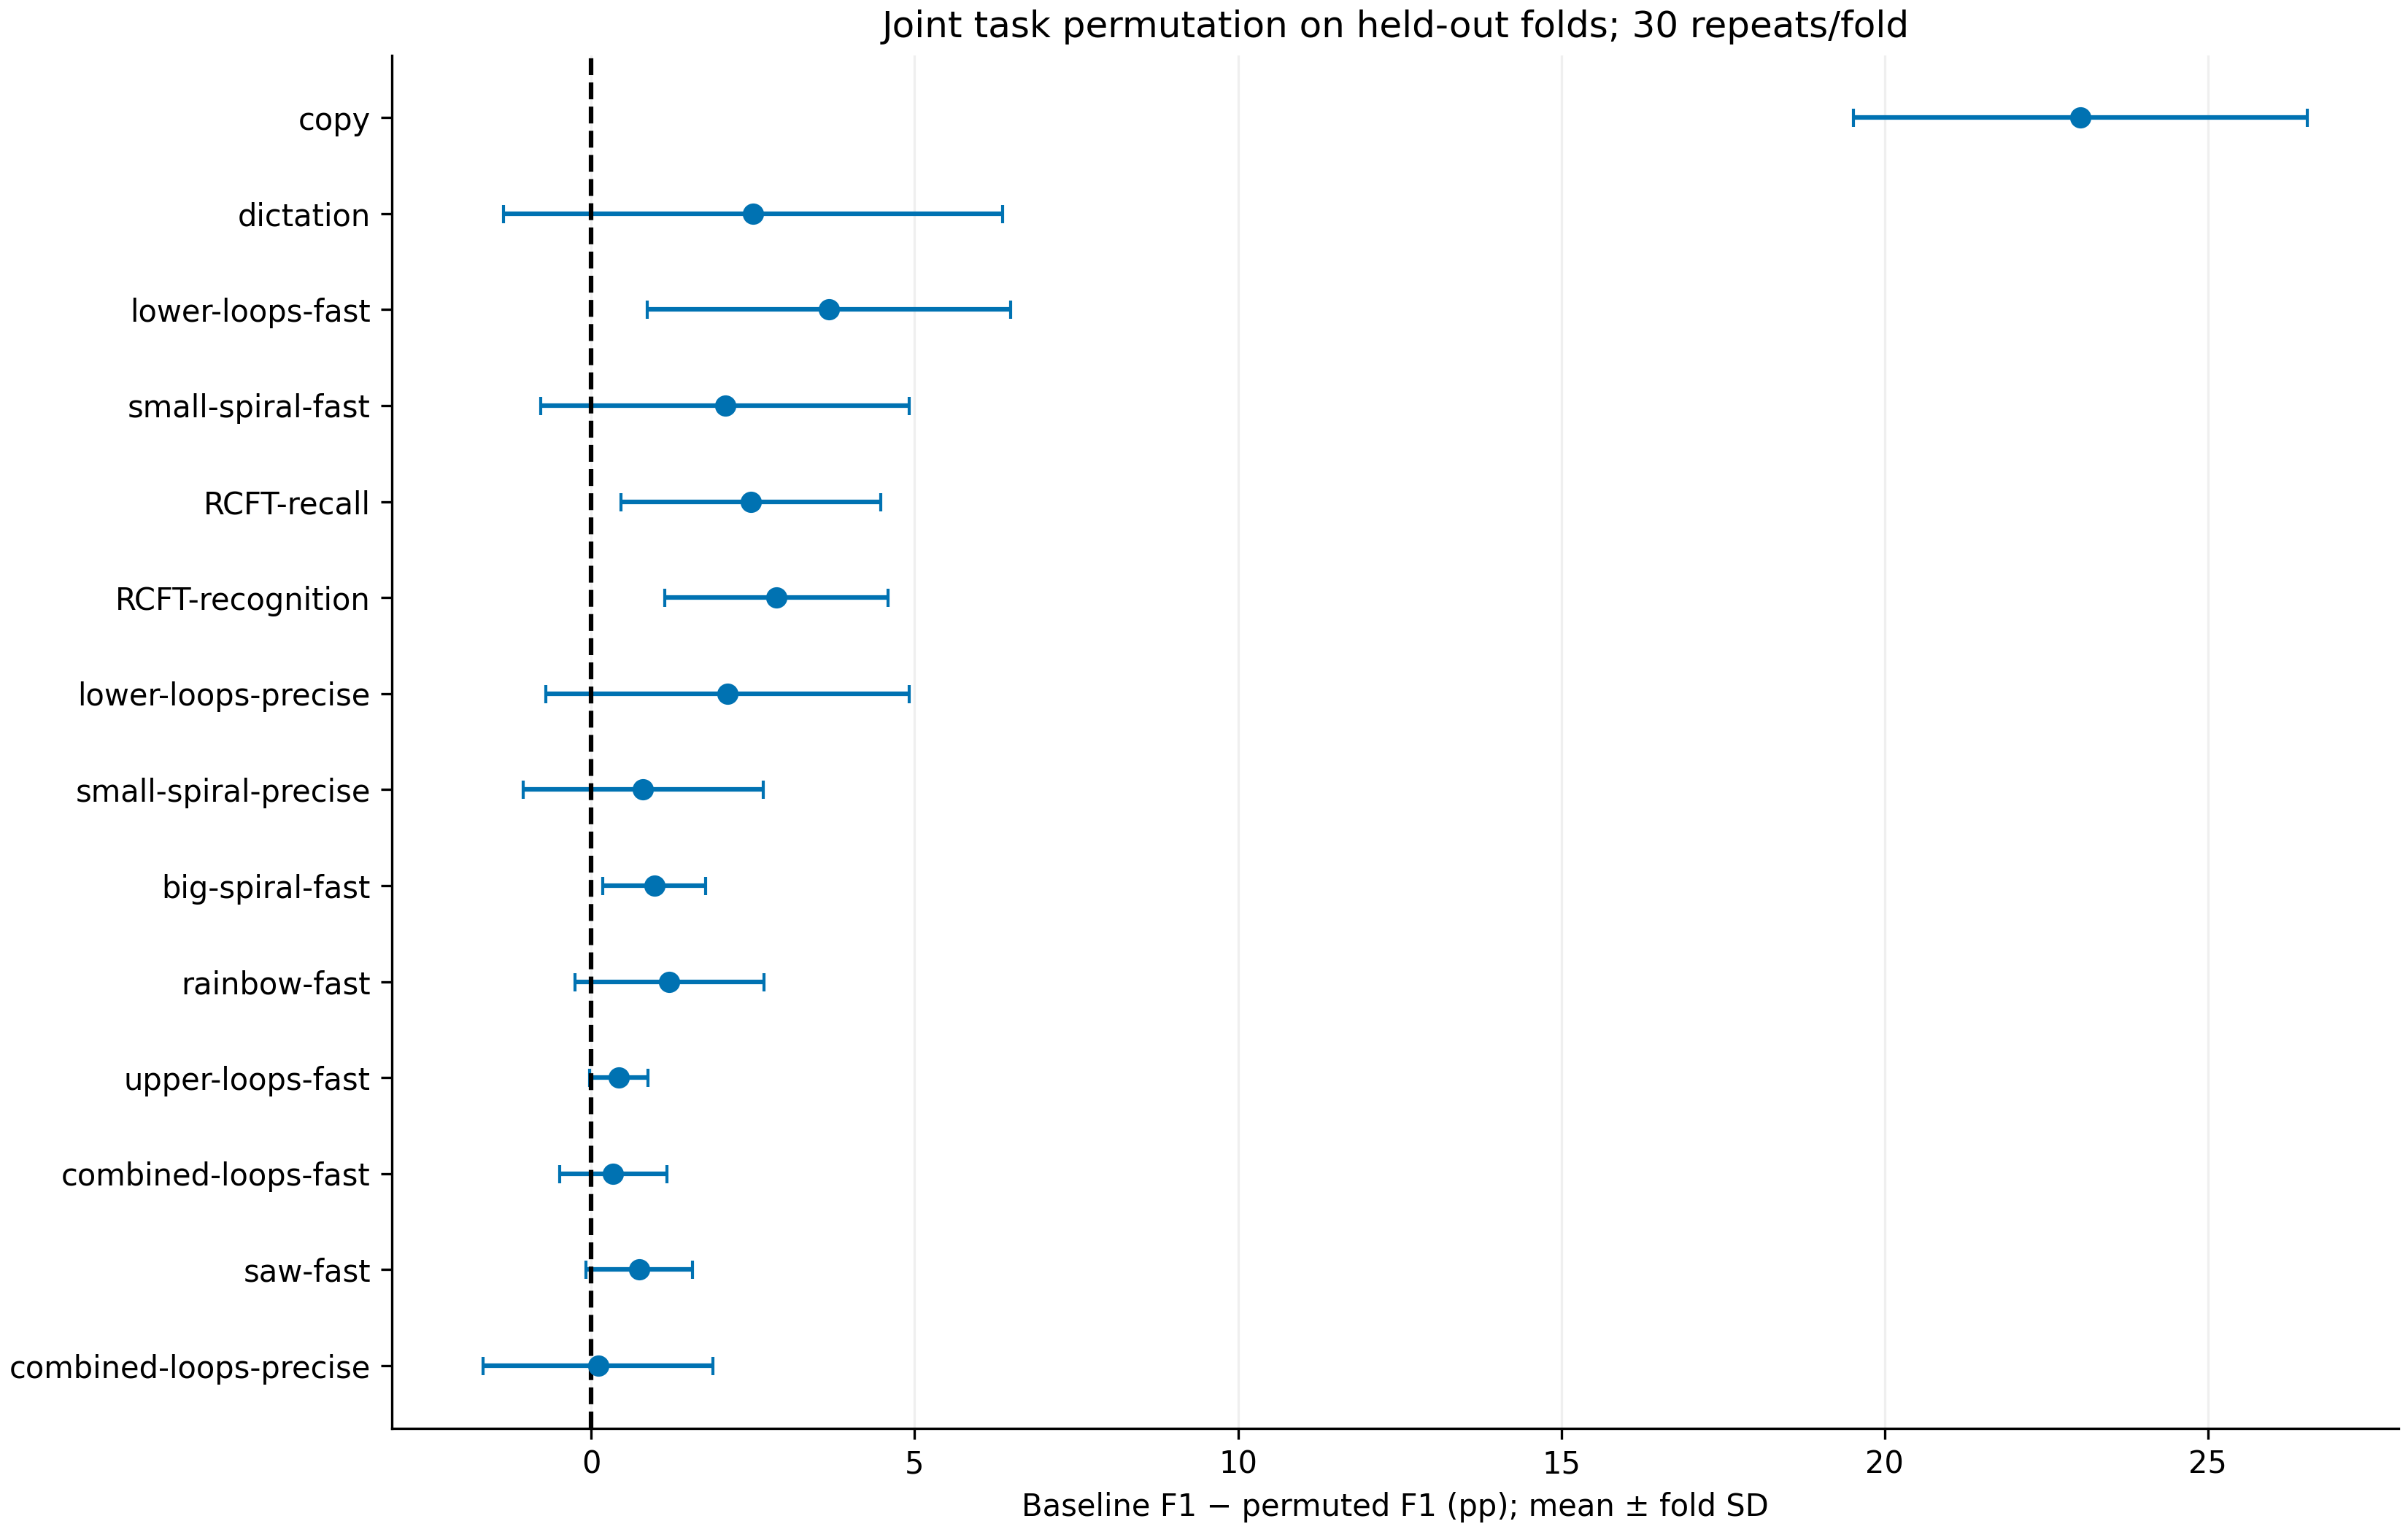

In [12]:
show_figures(['task_importance','feature_groups','task_group_heatmap','task_fold_ranks','grouped_permutation_tasks'])

## CWT giúp hoặc gây hại khi nào

**fusion_probability_correction** — Exact probability delta versus baseline confidence; participant outcomes are descriptive, not used to tune gates. Units: probability difference

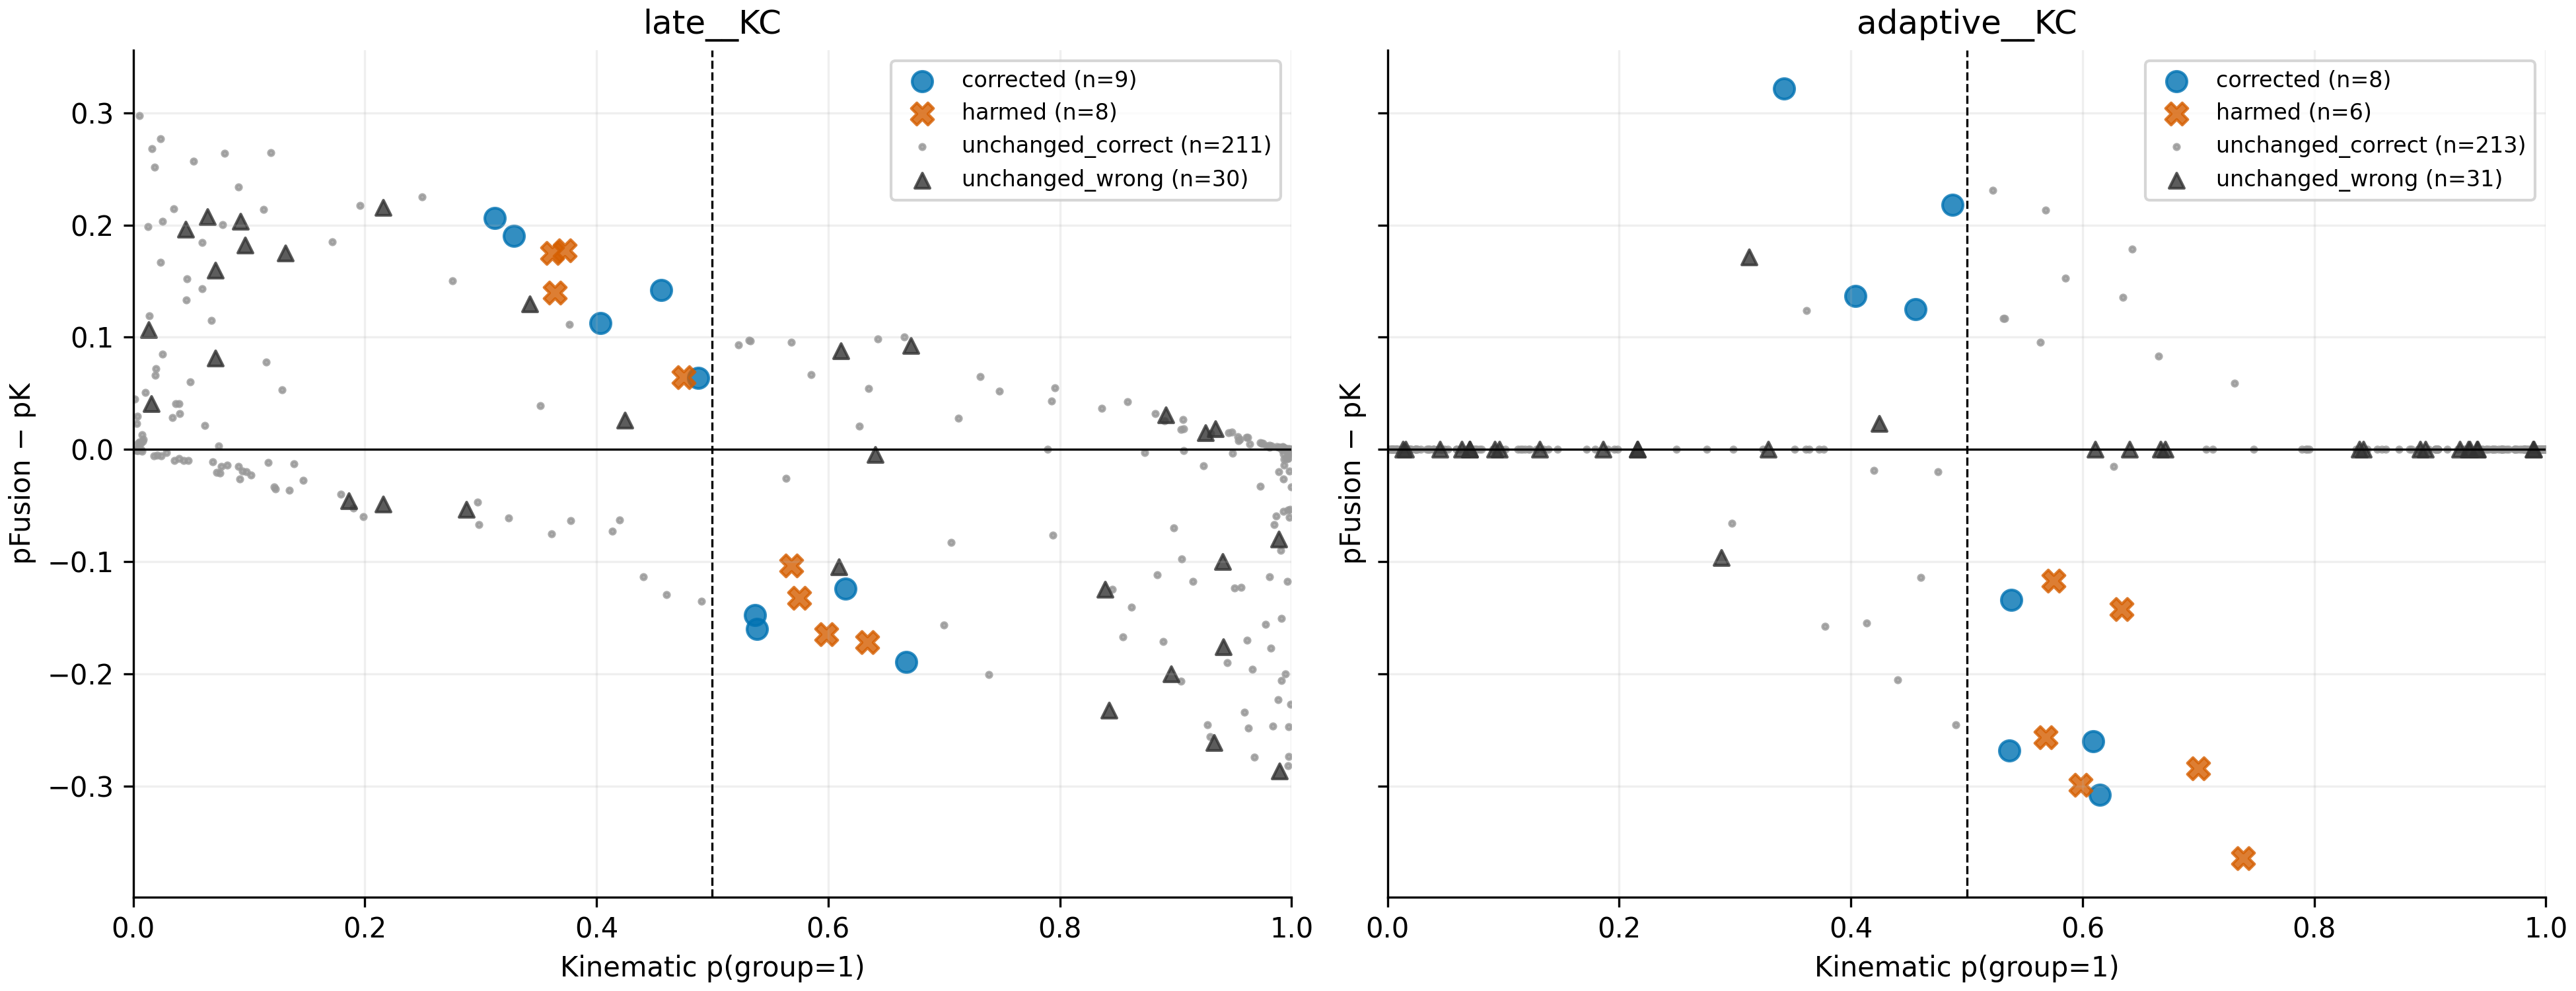

**fusion_corrected_harmed** — All four outcomes, including unchanged errors and corrections that harm baseline. Units: participant counts

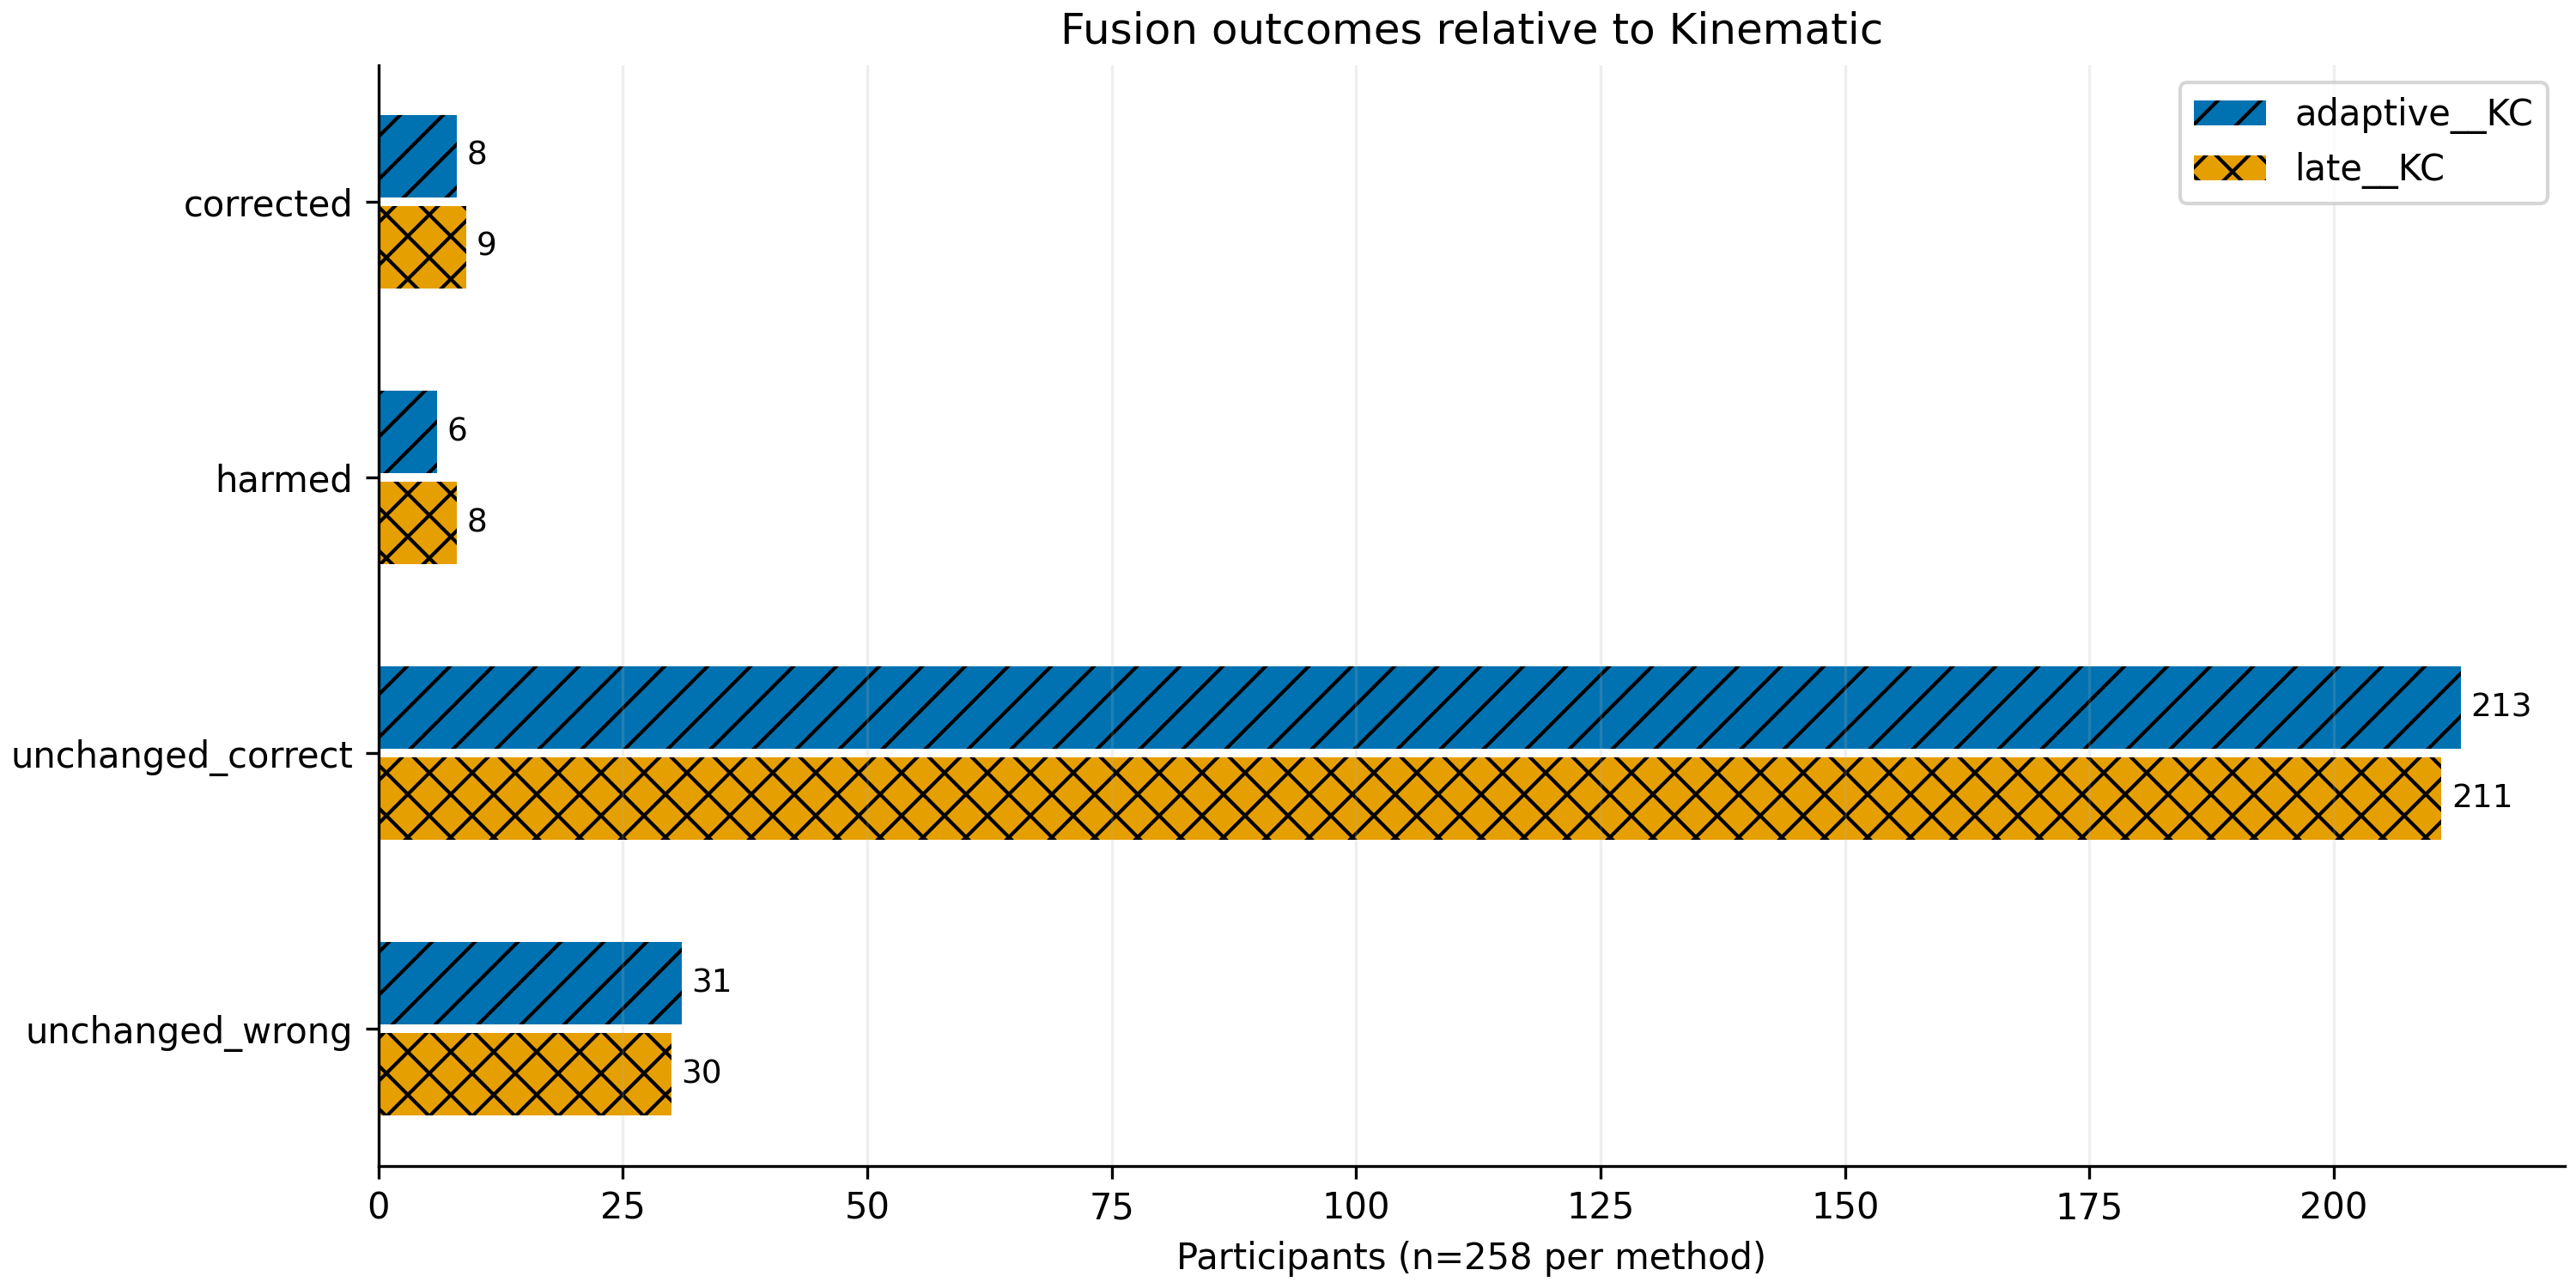

**cwt_pca_components** — Fold-specific PCA coordinates, 43 held-out participants per panel; PC indices not pooled across folds or mapped to biology/tasks. Units: CWT classifier log-odds

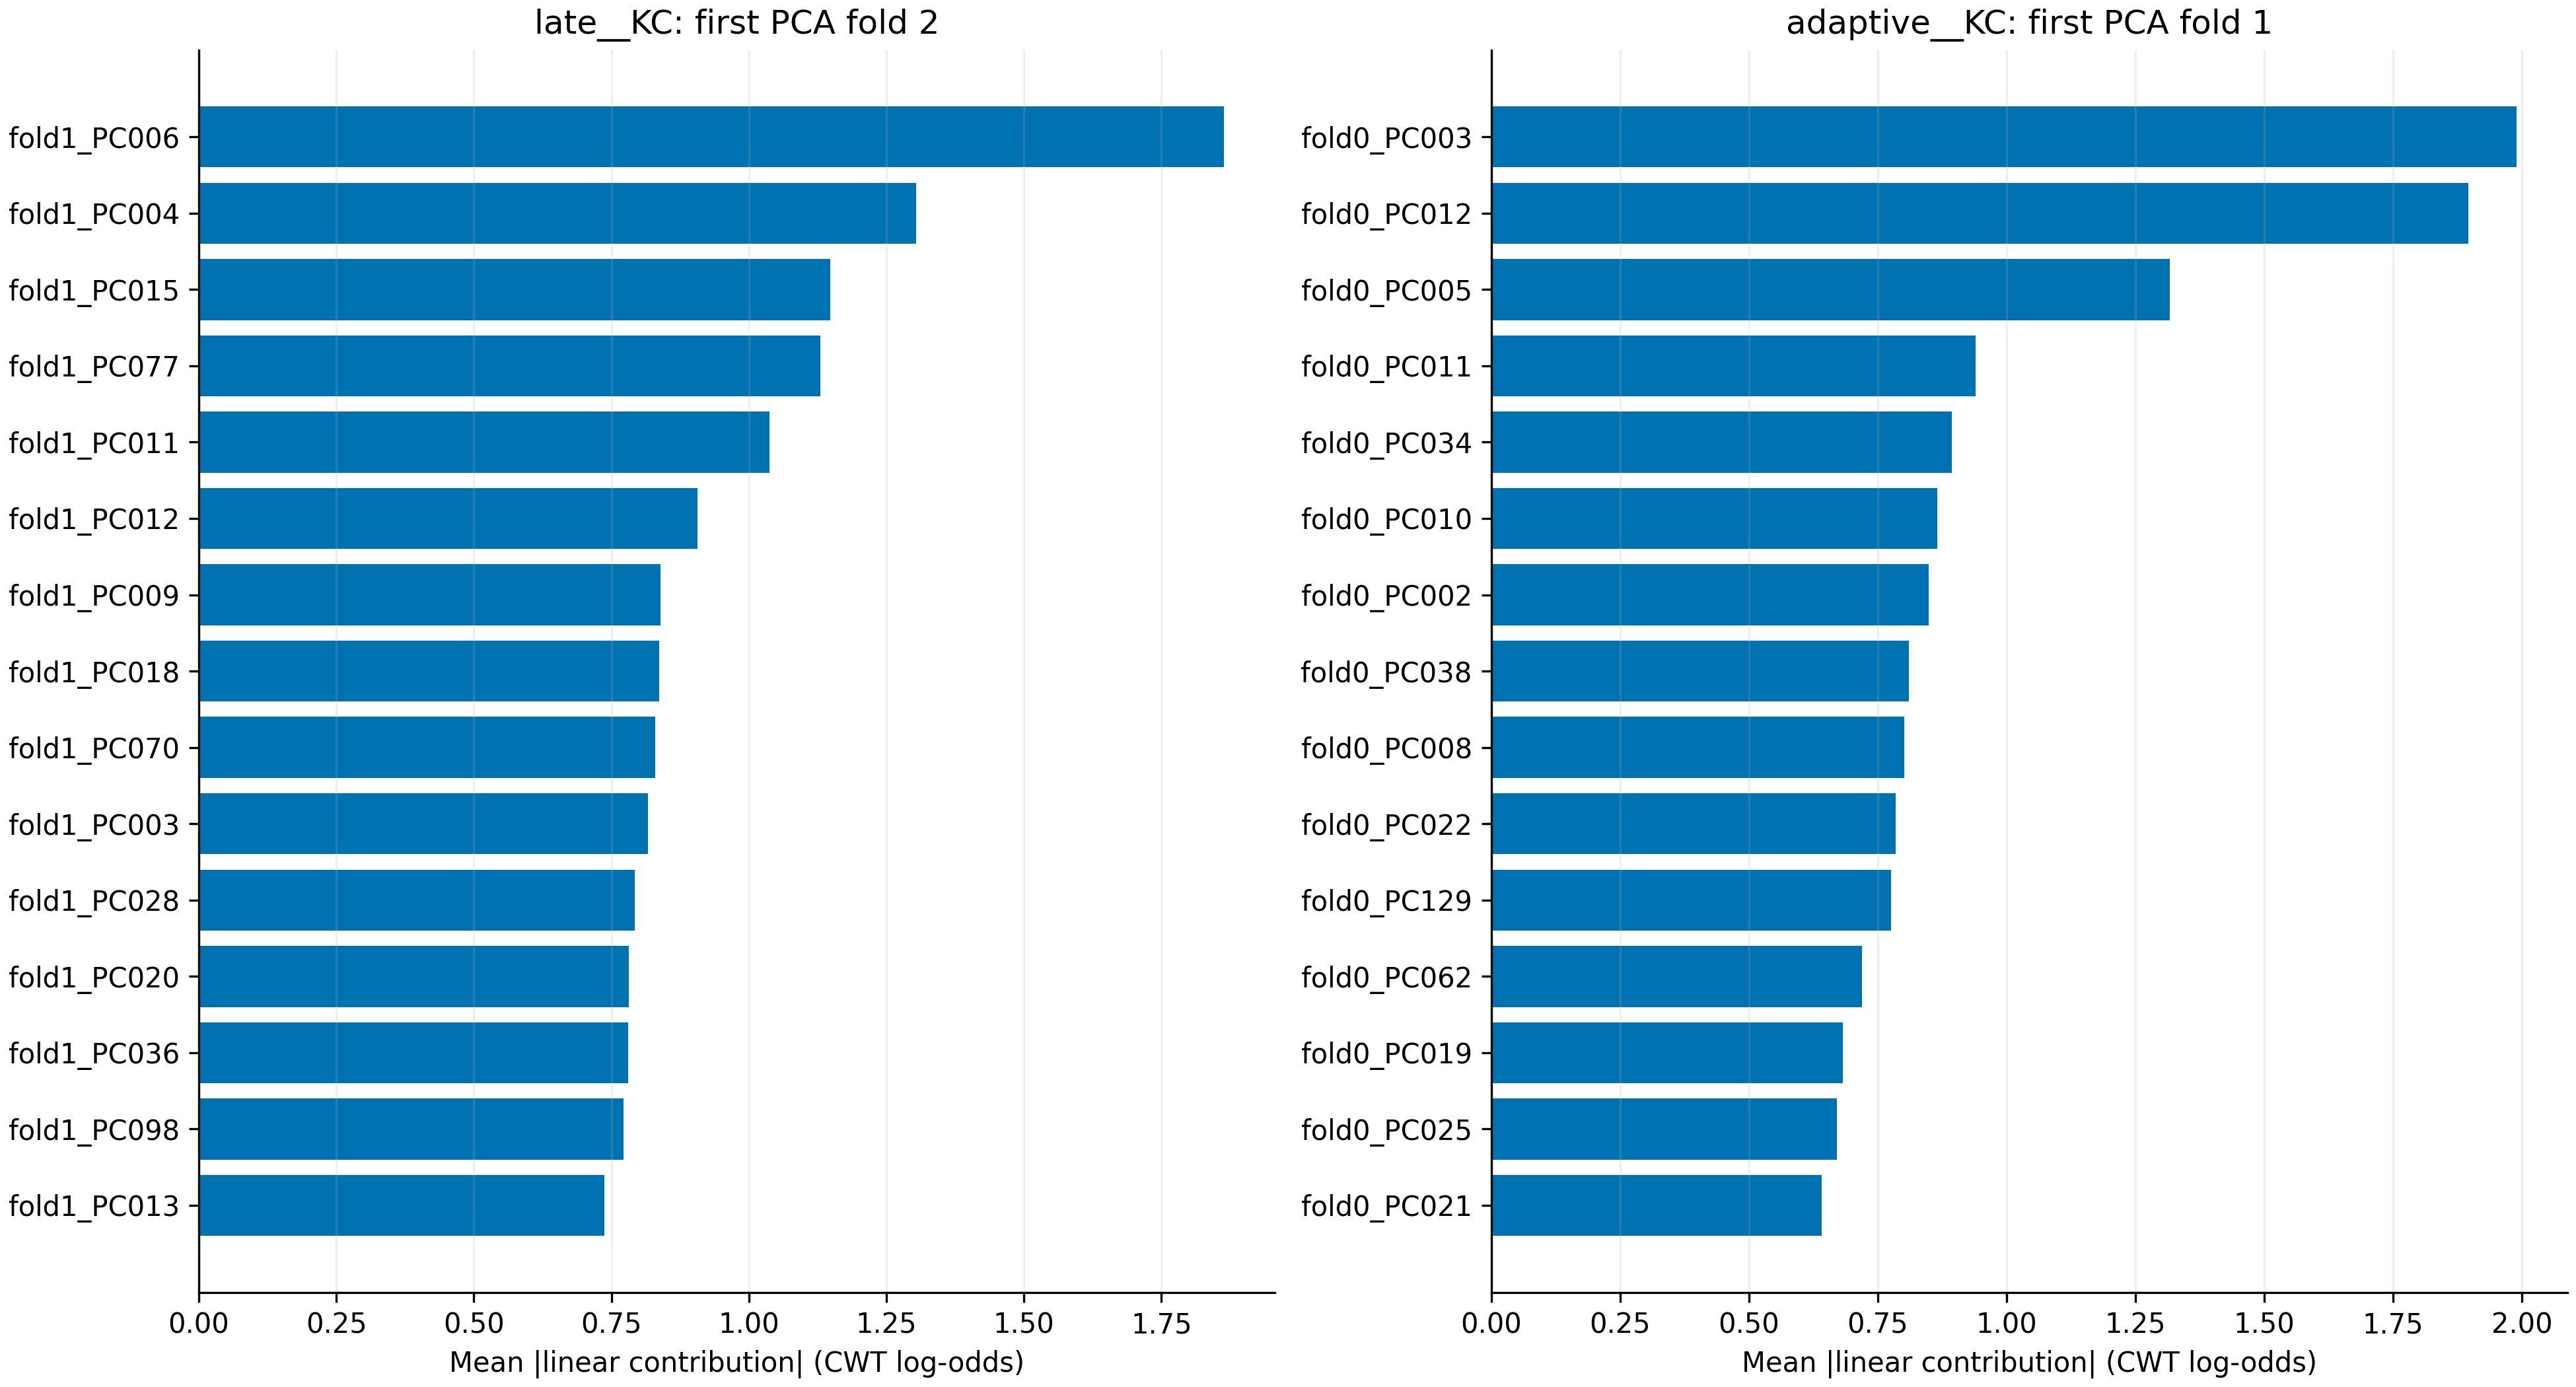

,scenario,distance_low,distance_high,n,corrected,harmed,mean_abs_delta_cwt
0,late__KC,0.000000,0.100000,21,5,4,0.100217
1,late__KC,0.100000,0.200000,22,4,4,0.109880
2,late__KC,0.200000,0.300000,17,0,0,0.092079
3,late__KC,0.300000,0.400000,33,0,0,0.093165
4,late__KC,0.400000,0.500000,165,0,0,0.076502
5,adaptive__KC,0.000000,0.100000,21,5,3,0.155242
6,adaptive__KC,0.100000,0.200000,22,3,1,0.086178
7,adaptive__KC,0.200000,0.300000,17,0,2,0.051131
8,adaptive__KC,0.300000,0.400000,33,0,0,0.000000
9,adaptive__KC,0.400000,0.500000,165,0,0,0.000000


In [13]:
show_figures(['fusion_probability_correction','fusion_corrected_harmed','cwt_pca_components'])
display(pd.read_csv(OUT/'fusion_confidence_bins.csv'))

## Kết luận và giới hạn

Không kết luận số task tối thiểu từ SHAP. Muốn giảm task cần thí nghiệm task ablation riêng,
chọn subset trong inner Train và xác nhận trên outer Test/cohort ngoài. Không tối ưu Accuracy
hoặc thay model trong notebook này. Đọc REPORT_VI.md cho khuyến nghị hình/bảng viết paper.

In [14]:
display(pd.DataFrame([{k:v for k,v in validation.items() if k!='numeric_artifact_sha256'}]))
print((OUT/'REPORT_VI.md').read_text(encoding='utf-8').split('## Mapping')[0])

,complete,stage,numerical_validation_passed,n_subjects,outer_folds,seed,n_features,n_tasks,n_source_groups,outer_test_attribution_rows,fusion_rows,permutation_blocks,permutation_repeats_per_block_fold,permutation_evaluations,baseline_oof_matches,fusion_oof_matches,shap_additivity_passed,cwt_linear_additivity_passed,all_permutations_replayed,mapping_source_sentinels_passed,train_only_backgrounds_verified,original_artifacts_unchanged
0,False,numerical_validation_passed,True,258,6,42,1036,14,12,258,516,26,30,4680,True,True,True,True,True,True,True,1288


# Explainable AI — Kinematic và Fusion Kinematic+CWT

## Kết quả chính và phạm vi

Giải thích **mô hình đã đánh giá**, không thay kiến trúc, classifier, reducer, trọng số hoặc threshold.
Giữ **258 participant, nhãn group, sáu outer folds và seed 42**. Attribution chỉ tính trên 43 outer Test
của mô hình fit trên 215 outer Train tương ứng. Baseline OOF và hai Fusion được replay khớp trước giải thích.
Trạng thái cuối cùng chỉ lấy từ `validation.json complete=true`, sau tests, notebook và hình.

Theo attribution mass của raw TreeSHAP OOF, ba tác vụ đứng đầu là **copy, dictation, lower-loops-fast**,
chiếm **54.89%** tổng mean absolute attribution. Ba nhóm có tổng mass cao nhất là **FFT, Statistics, Trajectory**.
Đây là mô tả việc mô hình sử dụng thông tin, không phải bằng chứng nhân quả, biomarker hay chẩn đoán lâm sàng.


